# Tema 4 · Validez de las noticias y los datos alternativos (B2)

**Fase 2 del TFM** (datos de los agentes) · rama `fase2/t4-noticias-alt` · código en
`src/ingesta/noticias_alt/validez.py` (cálculo) y `graficos.py` (figuras).

La sonda (notebook `t4_01`) responde a *qué hay, desde cuándo y con qué retraso*. Este notebook responde a otra
pregunta: **¿sirve cada fuente para el backtest, solo para el vivo o para nada?** «Validez» se mide aquí en cuatro
niveles y se resume en un semáforo:

| Nivel | Pregunta | Tablas |
|---|---|---|
| 1. Calidad | ¿Huecos, atípicos, saltos de nivel, valores repetidos, vintages revisados? | `validez_calidad` |
| 2. Look-ahead | ¿La fecha de publicación es la que un agente habría visto? ¿Alguna normalización mira el futuro? | `validez_lookahead` |
| 3. Señal frente a crisis | ¿Se mueve en las crisis de la Fase 1? ¿Antes o después del VIX? ¿Es estable? | `validez_eventos`, `validez_auc`, `validez_leadlag`, `validez_estabilidad` |
| 4. Medida propia | Mercados de predicción: ¿están calibrados? Congreso e insiders: ¿hay rentabilidad anormal **desde la publicación**? | `validez_calibracion`, `validez_fiabilidad_bins`, `validez_car` |
| Semáforo | `apta_backtest` · `contexto` · `solo_vivo` · `descartar` | `validez_semaforo` |

**Todo es causal.** Las series se colocan en una rejilla diaria de días hábiles *as-of* por `fecha_publicacion`
(el último dato publicado hasta ese día, nunca por `fecha_referencia`), y el z de cada serie es *expanding*
(solo pasado), con un mínimo de observaciones. Una decisión sí mira la serie entera: si el z se calcula sobre el
logaritmo (asimetría de toda la serie). El apartado 3 rehace el pipeline en varios cortes solo con lo publicado hasta
cada corte y marca en `riesgo` las series en que el z cambia.

**Advertencias antes de leer las cifras:**

- *Data-snooping.* Se prueban decenas de series y tres adelantos. Para no elegir a posteriori, el semáforo puntúa
  solo el adelanto 0, en el sentido fijado de antemano para cada familia de series (`validez.SIGNO_ESPERADO`), y
  exige que el intervalo excluya 0,5 y que el estudio de eventos vaya en el mismo sentido. Sigue siendo una criba.
- *Poca potencia.* Las crisis son pocas y muchas fuentes solo cubren unas cuantas: el n efectivo del AUC es el número
  de crisis, no el de días, y su intervalo remuestrea crisis completas; el del CAR remuestrea semanas completas
  (eventos agrupados en el tiempo). Los intervalos anchos son la lectura correcta.
- Los umbrales del semáforo son reglas fijadas antes de mirar los resultados (constantes del módulo, impresas abajo),
  pero condicionan el veredicto.

Con `EJECUTAR = False` el notebook **solo lee** `results/ingesta/noticias_alt/validez_*.csv` y las series del corpus;
con `True` recalcula antes las tablas con `validez.ejecutar()`.

In [1]:
%matplotlib inline
import sys
import warnings
from pathlib import Path

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ingesta' / 'noticias_alt').is_dir()),
            Path.cwd())
if str(RAIZ / 'src') not in sys.path:
    sys.path.insert(0, str(RAIZ / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ingesta.comun.rutas import resultados_dir
from ingesta.noticias_alt import base, graficos as gr, validez as va
from ingesta.noticias_alt.muestra import crisis_fase1

gr.estilo(dpi=90)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.max_rows', 120)

EJECUTAR = False   # True: recalcula los validez_*.csv (corpus + precios cacheados de yfinance; unos minutos)
if EJECUTAR:
    va.ejecutar()

RES = resultados_dir(base.TEMA)
NOMBRES = ['validez_calidad', 'validez_lookahead', 'validez_eventos', 'validez_auc', 'validez_leadlag',
           'validez_leadlag_resumen', 'validez_estabilidad', 'validez_calibracion', 'validez_fiabilidad_bins',
           'validez_car', 'validez_car_eventos', 'validez_semaforo', 'ews_z', 'ews_alarmas',
           'congreso_ptr_anio', 'congreso_operaciones']
faltan = [n for n in NOMBRES if not (RES / f'{n}.csv').exists()]
if faltan:
    raise FileNotFoundError(f'Faltan tablas en {RES}: {faltan}. Primero la sonda (python -m ingesta.noticias_alt.sonda) '
                            'y después python -m ingesta.noticias_alt.validez')
T = {n: pd.read_csv(RES / f'{n}.csv') for n in NOMBRES}
CRISIS = crisis_fase1('A')
HOY = pd.Timestamp.today().normalize()
print(f'{len(T)} tablas leídas de results/ingesta/{base.TEMA}:')
for n, d in T.items():
    print(f'  {n:26s} {len(d):>7,} filas')

16 tablas leídas de results/ingesta/noticias_alt:
  validez_calidad                 51 filas
  validez_lookahead              116 filas
  validez_eventos              5,324 filas
  validez_auc                    132 filas
  validez_leadlag             42,108 filas
  validez_leadlag_resumen        174 filas
  validez_estabilidad            215 filas
  validez_calibracion             24 filas
  validez_fiabilidad_bins         60 filas
  validez_car                     12 filas
  validez_car_eventos            212 filas
  validez_semaforo                81 filas
  ews_z                       14,335 filas
  ews_alarmas                      4 filas
  congreso_ptr_anio               13 filas
  congreso_operaciones           531 filas


In [2]:
param = {
    'crisis de la Fase 1 (pista A, ventanas pico → suelo)': f'{len(CRISIS)}',
    'rejilla': f'días hábiles desde {va.INICIO_REJILLA}, as-of por fecha_publicacion',
    'vigencia de un dato publicado': f'{va.VIGENCIA_FACTOR} espaciados típicos (mínimo {va.VIGENCIA_MIN} días hábiles)',
    'z causal': f'expanding, mínimo {va.MIN_OBS_Z} observaciones',
    'adelantos del AUC (días hábiles)': ', '.join(map(str, va.ADELANTOS)),
    'ventana del estudio de eventos (días hábiles)': f'{va.VENTANA_EVENTOS[0]} … +{va.VENTANA_EVENTOS[1]}',
    'IC del estudio de eventos': f't de Student al {va.NIVEL_IC:.0%} entre crisis, solo con ≥ {va.CRISIS_BUENA} crisis',
    'IC del AUC': f'bootstrap de crisis completas al {va.NIVEL_IC:.0%}, {va.N_BOOT_AUC} remuestras',
    'IC del CAR': f'bootstrap de semanas completas al {va.NIVEL_IC:.0%}, {va.N_BOOT} remuestras',
    'atípico': f'|z robusto (MAD) de las diferencias| > {va.UMBRAL_ATIPICO:g}',
    'ruptura candidata': f'salto de media entre ventanas > {va.UMBRAL_RUPTURA:g} desviaciones',
    'semáforo · historia': f'≥ {va.CRISIS_BUENA} crisis cubiertas → 2; ≥ {va.CRISIS_REGULAR} → 1; menos → 0',
    'semáforo · señal de series (1)': f'AUC con adelanto 0 en los días del VIX, solo en el sentido esperado',
    'semáforo · señal de series (2)': f'signo·(AUC − 0,5) ≥ {va.AUC_BUENA:g} → 2; ≥ {va.AUC_REGULAR:g} → 1',
    'semáforo · señal de series (3)': f'y IC sin 0,5 y estudio de eventos (días {va.VENTANA_SIGNO[0]}..+{va.VENTANA_SIGNO[1]}) del mismo signo',
    'semáforo · señal del CAR': f'IC sin el 0 en ≥ 2 de {len(va.HORIZONTES_CAR)} horizontes, mismo signo; ≤ {va.MAX_SIN_PRECIO:.0%} sin precio',
    'semáforo · señal de predicción': f'Brier < climatológico entre ≥ {va.MIN_INDECISOS} mercados indecisos a 7 d',
    'mercado indeciso': f'probabilidad entre {va.PROB_INDECISA[0]:g} y {va.PROB_INDECISA[1]:g}',
    'semáforo · huecos': f'≤ {va.HUECOS_BUENO:.0%} → 2; ≤ {va.HUECOS_REGULAR:.0%} → 1',
    'semáforo · racha constante': f'≥ {va.RACHA_MALA} valores idénticos seguidos → calidad 0',
    'corte de estabilidad': f'antes / desde {va.CORTE_ESTABILIDAD} y por décadas',
}
display(pd.Series(param, name='valor').rename_axis('parámetro (constantes de validez.py)').to_frame())
display(pd.DataFrame(va.SIGNO_ESPERADO, columns=['patrón de la serie', 'signo esperado en crisis', 'motivo'])
        .style.hide(axis='index').set_caption('validez.SIGNO_ESPERADO (fijado por la definición de cada índice)'))

,valor
parámetro (constantes de validez.py),
"crisis de la Fase 1 (pista A, ventanas pico → suelo)",18
rejilla,"días hábiles desde 1985-01-01, as-of por fecha_publicacion"
vigencia de un dato publicado,3 espaciados típicos (mínimo 5 días hábiles)
z causal,"expanding, mínimo 252 observaciones"
adelantos del AUC (días hábiles),"0, 20, 60"
ventana del estudio de eventos (días hábiles),-60 … +60
IC del estudio de eventos,"t de Student al 90% entre crisis, solo con ≥ 5 crisis"
IC del AUC,"bootstrap de crisis completas al 90%, 500 remuestras"
IC del CAR,"bootstrap de semanas completas al 90%, 2000 remuestras"


patrón de la serie,signo esperado en crisis,motivo
^vix_,1,volatilidad implícita: sube con el estrés
^skew$,-1,SKEW: la prima de cola relativa cae cuando la volatilidad ATM ya se ha disparado
^pc_.*_(ratio|puts)$,1,put/call y volumen de puts: cobertura en las caídas
^(epu|gepu),1,incertidumbre de política económica
^gpr,1,"riesgo geopolítico (índices y subíndices por país, actos y amenazas)"
^wiki_pv:,1,atención a temas de crisis (visitas)
^gdelt_tono,-1,tono de las noticias: más negativo con el estrés
^ews_,1,actividad de jets privados (botón de cataclismo)
^polymarket_recesion,1,probabilidad de recesión
^polymarket_fed_recorte,1,probabilidad de recortes de tipos


## 1. Series disponibles

Cada serie del corpus (`D:/tfm_corpus/noticias_alt/series/*.parquet`, tabla larga) con su frecuencia, su historia,
el retraso de publicación medido (`fecha_publicacion − fecha_referencia`) y las crisis de la Fase 1 que cubre en la
rejilla. La columna `transformacion` dice si el z se calcula sobre el logaritmo (series positivas muy asimétricas:
conteos y visitas).

In [3]:
CAL = T['validez_calidad'].copy()
AUC = T['validez_auc']
SEM = T['validez_semaforo']
N_CRISIS = AUC.groupby('serie')['n_crisis'].max()
tabla1 = (CAL.assign(crisis_cubiertas=CAL['serie'].map(N_CRISIS).astype('Int64'))
          [['serie', 'fuente', 'fichero', 'frecuencia', 'inicio', 'fin', 'n', 'lag_pub_mediana_dias',
            'lag_pub_max_dias', 'transformacion', 'crisis_cubiertas']]
          .sort_values(['fuente', 'serie']).reset_index(drop=True))
display(tabla1)
print(f'{len(CAL)} series de {CAL["fuente"].nunique()} fuentes en {CAL["fichero"].nunique()} ficheros · '
      'frecuencias: ' + ', '.join(f'{k} {v}' for k, v in CAL['frecuencia'].value_counts().items()))

,serie,fuente,fichero,frecuencia,inicio,fin,n,lag_pub_mediana_dias,lag_pub_max_dias,transformacion,crisis_cubiertas
0,pc_equity_calls,cboe_putcall,cboe_putcall_equity,diaria_habil,2006-11-01,2019-10-04,3253,1.0,4.0,nivel,6
1,pc_equity_puts,cboe_putcall,cboe_putcall_equity,diaria_habil,2006-11-01,2019-10-04,3253,1.0,4.0,nivel,6
2,pc_equity_ratio,cboe_putcall,cboe_putcall_equity,diaria_habil,2006-11-01,2019-10-04,3253,1.0,4.0,nivel,6
3,pc_index_calls,cboe_putcall,cboe_putcall_index,diaria_habil,2006-11-01,2019-10-04,3253,1.0,4.0,nivel,6
4,pc_index_puts,cboe_putcall,cboe_putcall_index,diaria_habil,2006-11-01,2019-10-04,3253,1.0,4.0,nivel,6
5,pc_index_ratio,cboe_putcall,cboe_putcall_index,diaria_habil,2006-11-01,2019-10-04,3253,1.0,4.0,nivel,6
6,pc_total_calls,cboe_putcall,cboe_putcall_total,diaria_habil,2006-11-01,2019-10-04,3253,1.0,4.0,nivel,6
7,pc_total_puts,cboe_putcall,cboe_putcall_total,diaria_habil,2006-11-01,2019-10-04,3253,1.0,4.0,nivel,6
8,pc_total_ratio,cboe_putcall,cboe_putcall_total,diaria_habil,2006-11-01,2019-10-04,3253,1.0,4.0,nivel,6
9,skew,cboe_skew,cboe_skew,diaria_habil,1990-01-02,2026-10-13,9247,1.0,4.0,nivel,12


51 series de 13 fuentes en 23 ficheros · frecuencias: diaria 23, mensual 15, diaria_habil 13


**Cómo leerlo.** Pequeños múltiplos de una serie representativa por fichero, tal como la vería un agente: valor
*as-of* por fecha de publicación en la rejilla de días hábiles (media semanal si la serie es larga). Las bandas rojas
son las crisis de la Fase 1. Arriba, las fuentes con historia larga (eje desde 1985); abajo, las recientes (eje común
desde 2014). Un tramo vacío indica un hueco o una fuente congelada: el dato deja de valer pasado su plazo de
vigencia (p. ej. los huecos del archivo de Truth Social).
Las series con menos de 30 días con dato en la rejilla no se dibujan (un panel vacío parece un error del gráfico):
se imprimen debajo con su motivo, p. ej. un vintage único guardado con la fecha de hoy, que en el pasado no existe.

Rejilla as-of: 51 series × 10,902 días hábiles (1985-01-01 → 2026-10-14)
Sin dibujar ews_z_publicado: 1 día(s) con dato en la rejilla as-of (metodo_publicacion: vintage_unico)


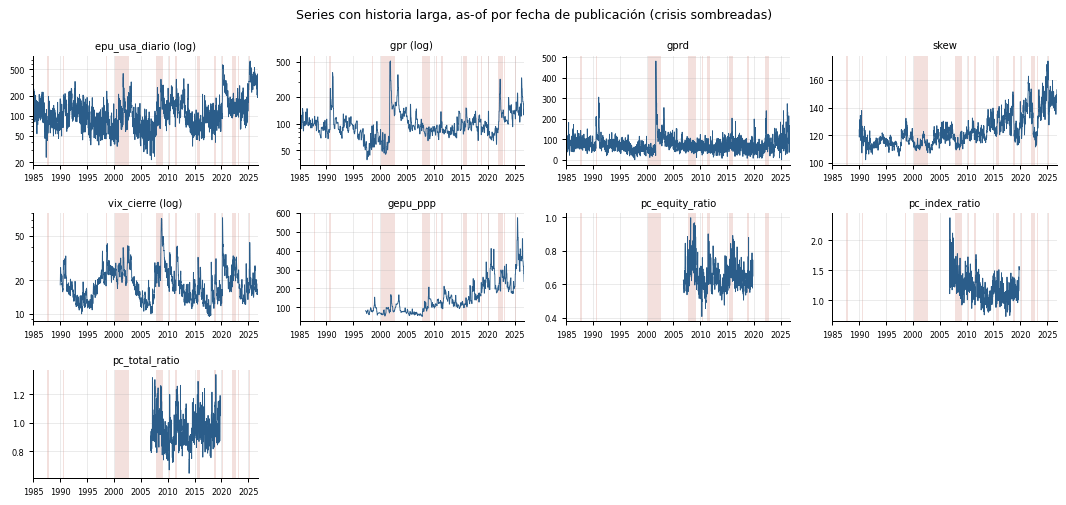

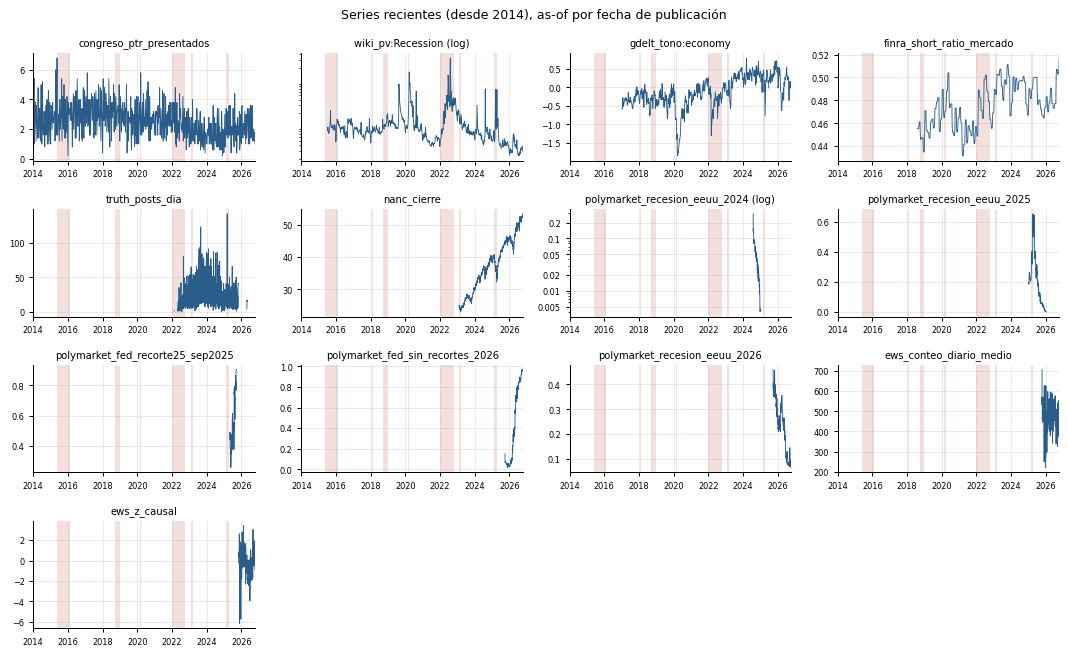

In [4]:
LARGAS = va.leer_corpus_series()
REJ, META = va.cargar_series(LARGAS)
print(f'Rejilla as-of: {REJ.shape[1]} series × {REJ.shape[0]:,} días hábiles '
      f'({REJ.index.min():%Y-%m-%d} → {REJ.index.max():%Y-%m-%d})')

PREFERIDA = {'wiki_pageviews': 'wiki_pv:Recession', 'ews_actividad': 'ews_conteo_diario_medio'}


def representante(series) -> str:
    """Una serie por fichero: la de ratio o cierre si la hay; si no, la de nombre más corto."""
    s = sorted(series)
    for clave in ('ratio', 'cierre'):
        c = [x for x in s if clave in x]
        if c:
            return c[0]
    return min(s, key=lambda x: (len(x), x))


REPR = {f: PREFERIDA.get(f) or representante(g['serie']) for f, g in CAL.groupby('fichero')}
TRANS = dict(zip(CAL['serie'], CAL['transformacion']))
INICIO = dict(zip(CAL['serie'], pd.to_datetime(CAL['inicio'])))
CORTE_LARGA = pd.Timestamp('2014-01-01')
FMT_LOG = plt.FuncFormatter(lambda v, _: f'{v:g}')
LOC_LOG = plt.LogLocator(base=10, subs=(1.0, 2.0, 5.0))


def multiples(nombres, desde, titulo, ncol=4):
    nrow = int(np.ceil(len(nombres) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(12, 1.7 * nrow + 0.6), sharex=True, squeeze=False)
    for ax, n in zip(axes.ravel(), nombres):
        s = REJ[n]
        s = s.loc[s.first_valid_index():s.last_valid_index()]   # los huecos quedan en NaN: sin línea
        if s.notna().sum() > 1500:   # figura ligera: media semanal
            s = s.resample('W').mean()
        ax.plot(s.index, s.values, lw=0.7, color=gr.C_BASE)
        if TRANS.get(n) == 'log' and s.notna().any() and (s.dropna() > 0).all():
            ax.set_yscale('log')
            ax.yaxis.set_major_locator(LOC_LOG)
            ax.yaxis.set_major_formatter(FMT_LOG)
            ax.yaxis.set_minor_formatter(plt.NullFormatter())
        gr.sombrear_crisis(ax, CRISIS, desde=desde)
        ax.set_xlim(pd.Timestamp(desde), REJ.index.max())
        ax.set_title(n + (' (log)' if TRANS.get(n) == 'log' else ''), fontsize=8)
        ax.tick_params(labelsize=6.5, labelbottom=True)
    for ax in axes.ravel()[len(nombres):]:
        ax.set_visible(False)
    fig.suptitle(titulo, fontsize=10)
    fig.tight_layout()
    return fig, axes


repr_ = sorted(REPR.values(), key=lambda n: (INICIO[n], n))
NOBS_REJ = REJ.notna().sum()
METODO = dict(zip(META['serie'], META['metodo_publicacion']))
for n in [n for n in repr_ if NOBS_REJ[n] < 30]:
    print(f'Sin dibujar {n}: {NOBS_REJ[n]} día(s) con dato en la rejilla as-of '
          f'(metodo_publicacion: {str(METODO.get(n, ""))[:70]})')
repr_ = [n for n in repr_ if NOBS_REJ[n] >= 30]
LARGAS_REPR = [n for n in repr_ if INICIO[n] < CORTE_LARGA]
CORTAS_REPR = [n for n in repr_ if INICIO[n] >= CORTE_LARGA]
multiples(LARGAS_REPR, '1985-01-01', 'Series con historia larga, as-of por fecha de publicación (crisis sombreadas)')
plt.show()
multiples(CORTAS_REPR, CORTE_LARGA, f'Series recientes (desde {CORTE_LARGA.year}), as-of por fecha de publicación')
plt.show()

In [5]:
lag_fuente = CAL.groupby('fuente')['lag_pub_mediana_dias'].median().sort_values()
print(f'{len(CAL)} series; {len(LARGAS_REPR)} de {len(REPR)} ficheros con historia anterior a {CORTE_LARGA.year}.')
print(f'Cubren ≥ {va.CRISIS_BUENA} crisis: {int((N_CRISIS >= va.CRISIS_BUENA).sum())} de {len(N_CRISIS)} series con z; '
      f'ninguna crisis: {int((N_CRISIS == 0).sum())}.')
print('Lag mediano de publicación por fuente (días): ' + ', '.join(f'{k} {v:g}' for k, v in lag_fuente.items()))

51 series; 9 de 23 ficheros con historia anterior a 2014.
Cubren ≥ 5 crisis: 39 de 44 series con z; ninguna crisis: 2.
Lag mediano de publicación por fuente (días): congreso_etfs_nanc_kruz 0, polymarket 0, ews 0.5, cboe_skew 1, cboe_vix 1, congreso_house_ptr 1, finra_short_volume 1, cboe_putcall 1, wiki_pageviews 1, truth_social_trump 1, gdelt_doc 5, gpr 31, epu 91


## 2. Calidad

Cada serie se mide en sus observaciones nativas (una por `fecha_referencia`, la última publicada):

- `pct_huecos`: observaciones que faltan frente a las esperadas por su frecuencia. En los conteos que solo guardan
  días con eventos (PTR del Congreso) un día sin fila es un 0, no un hueco.
- `pct_atipicos`: saltos con |z robusto (MAD) de las diferencias| por encima del umbral. Es un diagnóstico, no un filtro.
- `n_rupturas`: saltos de nivel candidatos (diferencia de medias entre ventanas).
- `pct_repetidos` y `racha_max_constante`: valores idénticos consecutivos (relleno o fuente parada).
- `lag_pub_mediana_dias`, `n_pub_antes_ref`: retraso de publicación y filas publicadas antes del hecho (deben ser 0).
- `revisable`: el valor guardado es el vintage de hoy (revisado después de publicarse).

**Cómo leerlo.** Verde = mejor dentro de cada columna (escala por columna: un verde en una columna no es comparable con
otro de otra). Las filas en rojo en `pct_huecos` o `n_rupturas` merecen mirarse a mano antes de usar la serie.

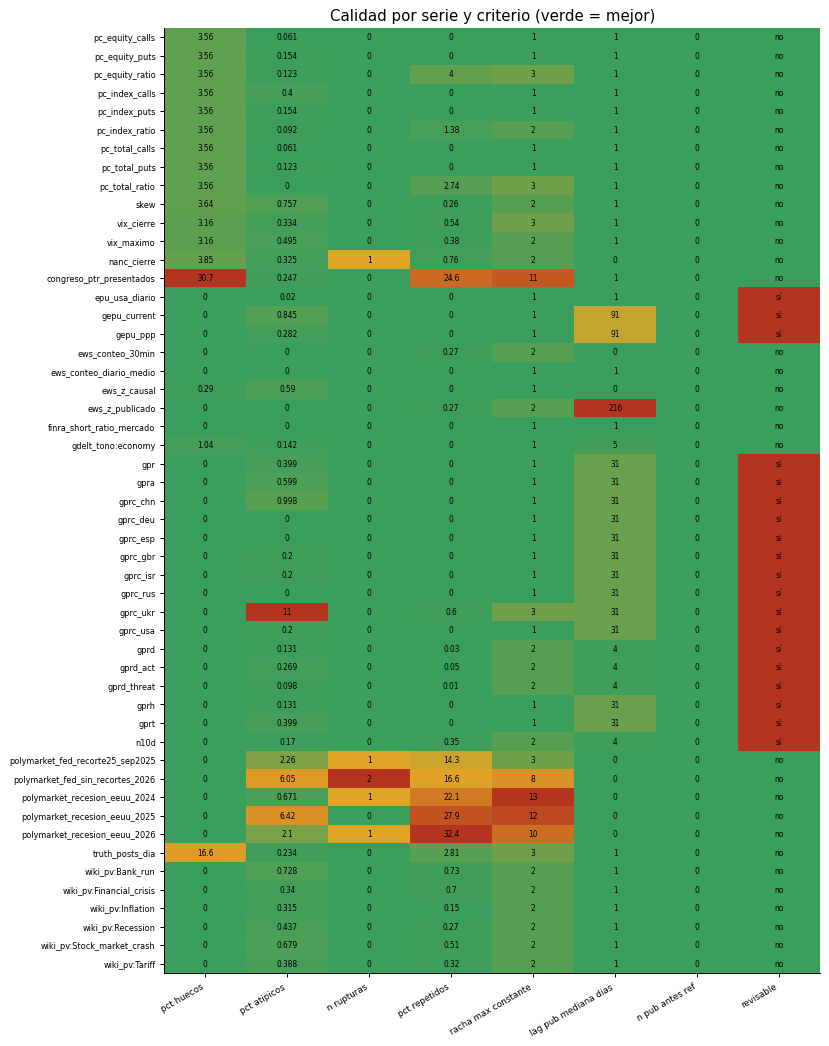

In [6]:
fig, ax = gr.calor_calidad(CAL.sort_values(['fuente', 'serie']))
plt.show()

**Cómo leerlo.** Ejemplos de las series con más rupturas y más atípicos (elegidas por la tabla, no a mano), en su
escala nativa y con la misma transformación que usa el z. Cruces rojas: atípicos; líneas discontinuas: rupturas
candidatas con su estadístico (diferencia de medias en desviaciones).

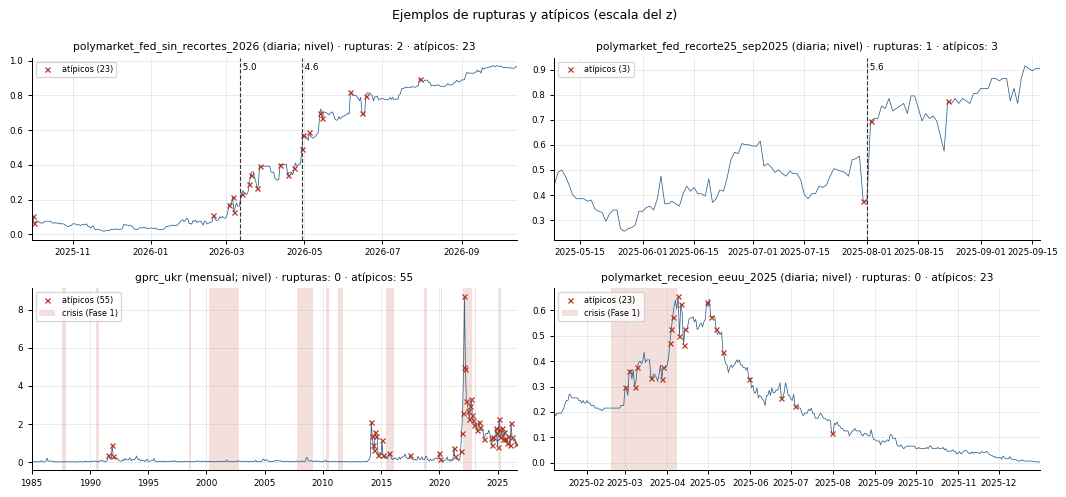

,serie,atipicos_tabla,atipicos_recalculados,rupturas_tabla,rupturas_recalculadas
0,polymarket_fed_sin_recortes_2026,23,23,2,2
1,polymarket_fed_recorte25_sep2025,3,3,1,1
2,gprc_ukr,55,55,0,0
3,polymarket_recesion_eeuu_2025,23,23,0,0


In [7]:
def nativa(nombre: str) -> pd.Series:
    """Observaciones nativas de una serie: una por fecha_referencia, la última publicada (como calidad_serie)."""
    g = LARGAS[LARGAS['serie'] == nombre].dropna(subset=['fecha_referencia']).copy()
    g['fecha_referencia'] = pd.to_datetime(g['fecha_referencia']).dt.normalize()
    orden = ['fecha_referencia'] + (['disponible_utc'] if 'disponible_utc' in g else [])
    g = g.sort_values(orden, kind='mergesort').groupby('fecha_referencia').last()
    return g['valor'].astype(float).dropna()


con_rup = CAL[CAL['n_rupturas'] > 0].sort_values(['n_rupturas', 'pct_atipicos'], ascending=False)['serie'].head(2).tolist()
con_ati = CAL[~CAL['serie'].isin(con_rup)].sort_values('pct_atipicos', ascending=False)['serie'].head(2).tolist()
EJEMPLOS = con_rup + con_ati
fig, axes = plt.subplots(2, 2, figsize=(12, 5.6))
comprobacion = []
for ax, n in zip(axes.ravel(), EJEMPLOS):
    v = nativa(n)
    vt = va.aplicar_transformacion(v, TRANS.get(n, 'nivel'))
    at = va.atipicos_mad(vt)
    rup = va.rupturas_media(vt)
    ax.plot(vt.index, vt.values, lw=0.6, color=gr.C_BASE)
    ax.plot(vt.index[at.values], vt[at.values].values, 'x', color=gr.C_CRISIS, ms=4, label=f'atípicos ({int(at.sum())})')
    for t, e in rup:
        ax.axvline(t, color='#333333', ls='--', lw=0.9)
        ax.text(t, 0.97, f' {e:.1f}', transform=ax.get_xaxis_transform(), fontsize=7, va='top')
    gr.sombrear_crisis(ax, CRISIS, desde=vt.index.min(), hasta=vt.index.max())
    ax.set_xlim(vt.index.min(), vt.index.max())
    fila = CAL.set_index('serie').loc[n]
    ax.set_title(f"{n} ({fila['frecuencia']}; {TRANS.get(n)}) · rupturas: {len(rup)} · atípicos: {int(at.sum())}", fontsize=8.5)
    ax.tick_params(labelsize=7)
    ax.legend(fontsize=6.5, loc='upper left')
    comprobacion.append(dict(serie=n, atipicos_tabla=int(fila['n_atipicos']), atipicos_recalculados=int(at.sum()),
                             rupturas_tabla=int(fila['n_rupturas']), rupturas_recalculadas=len(rup)))
fig.suptitle('Ejemplos de rupturas y atípicos (escala del z)', fontsize=10)
fig.tight_layout()
plt.show()
display(pd.DataFrame(comprobacion))

In [8]:
huecos = CAL[(CAL['pct_huecos'] > 100 * va.HUECOS_BUENO) & ~CAL['conteo_sin_ceros'].astype(bool)]
congeladas = CAL[pd.to_datetime(CAL['fin']) < HOY - pd.Timedelta(days=365)]
rev = CAL[CAL['revisable'].astype(bool)]
print(f'Huecos > {va.HUECOS_BUENO:.0%} (sin contar conteos): {len(huecos)} series '
      + (f'({", ".join(huecos["serie"])})' if len(huecos) else ''))
print(f'Conteos sin ceros (días sin fila = 0): {", ".join(CAL.loc[CAL["conteo_sin_ceros"].astype(bool), "serie"]) or "ninguno"}')
print(f'Rupturas candidatas: {int(CAL["n_rupturas"].sum())} en {int((CAL["n_rupturas"] > 0).sum())} series: '
      + '; '.join(f'{s} {f}' for s, f in CAL.loc[CAL['n_rupturas'] > 0, ['serie', 'fechas_rupturas']].values))
print(f'Atípicos: mediana {CAL["pct_atipicos"].median():.2f} % de las observaciones; máximo '
      f'{CAL["pct_atipicos"].max():.2f} % ({CAL.loc[CAL["pct_atipicos"].idxmax(), "serie"]}).')
print(f'Vintage actual (valor revisado): {len(rev)} series de las fuentes {", ".join(sorted(rev["fuente"].unique()))}.')
print(f'Congeladas (último dato hace más de un año): {", ".join(f"{s} ({f})" for s, f in congeladas[["serie", "fin"]].values) or "ninguna"}.')
print(f'Filas publicadas antes del hecho: {int(CAL["n_pub_antes_ref"].sum())}.')

Huecos > 10% (sin contar conteos): 1 series (truth_posts_dia)
Conteos sin ceros (días sin fila = 0): congreso_ptr_presentados
Rupturas candidatas: 6 en 5 series: nanc_cierre 2023-12-15(4.0); polymarket_fed_recorte25_sep2025 2025-08-01(5.6); polymarket_fed_sin_recortes_2026 2026-03-12(5.0);2026-04-29(4.6); polymarket_recesion_eeuu_2024 2024-09-09(4.5); polymarket_recesion_eeuu_2026 2026-06-14(4.9)
Atípicos: mediana 0.25 % de las observaciones; máximo 10.98 % (gprc_ukr).
Vintage actual (valor revisado): 19 series de las fuentes epu, gpr.
Congeladas (último dato hace más de un año): pc_equity_calls (2019-10-04), pc_equity_puts (2019-10-04), pc_equity_ratio (2019-10-04), pc_index_calls (2019-10-04), pc_index_puts (2019-10-04), pc_index_ratio (2019-10-04), pc_total_calls (2019-10-04), pc_total_puts (2019-10-04), pc_total_ratio (2019-10-04), polymarket_fed_recorte25_sep2025 (2025-09-17), polymarket_recesion_eeuu_2024 (2024-12-31).
Filas publicadas antes del hecho: 0.


## 3. Look-ahead

Una fila por comprobación y fuente, cada una con su evidencia medida. Las comprobaciones son de cuatro tipos:

- **Fechas**: `fecha_publicacion ≥ fecha_referencia` en todas las series y documentos; el campo de fecha que usa el
  TimeGate en cada fuente (`timegate.csv` de la sonda); GDELT por `DATEADDED` y no por `SQLDATE`; Wikipedia Current
  Events publicada en D+1; Congreso por fecha de presentación (no de operación) y Form 4 por aceptación en EDGAR.
- **Valores revisados**: series guardadas con el vintage de hoy (fecha correcta, valor no *point-in-time*).
- **Normalizaciones**: el pipeline entero (rejilla as-of, vigencia del dato, conteos sin ceros, transformación log
  o nivel y z expanding) se rehace en tres cortes solo con lo publicado hasta cada corte y se compara con el de la
  muestra entera; una serie cuyo z cambia queda en `riesgo` con su evidencia.
- **Riesgos documentados** de fuentes no medibles aquí (Google Trends reescala cada consulta).

**Cómo leerlo.** `ok` verde, `riesgo` ámbar (se puede usar con la precaución que dice la evidencia), `fallo` rojo
(descarta la fuente). La tabla resume por comprobación; la matriz muestra solo las fuentes con algún riesgo.

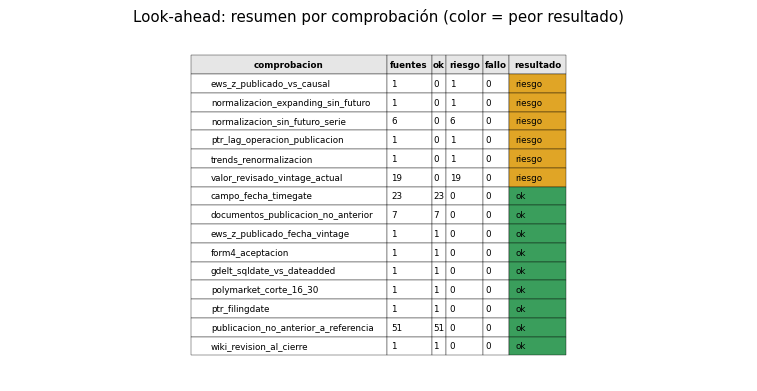

,comprobacion,resultado,evidencia (peor caso)
0,ews_z_publicado_vs_causal,riesgo,"12991 semihoras: corr 0.60, |dif| media 0.70; alarmas z>=2.0: publicado 275, causal 504. El z publicado se..."
1,normalizacion_expanding_sin_futuro,riesgo,"pipeline completo rehecho en 3 cortes solo con lo publicado hasta cada corte (rejilla, vigencia, conteos, ..."
2,normalizacion_sin_futuro_serie,riesgo,máx |z(hasta t) − z(muestra entera)| = 0.658; 0 días con dato en un pipeline y no en el otro; cortes 1997-...
3,ptr_lag_operacion_publicacion,riesgo,"lag operación->publicación: mediana 41 d, p90 329 d, 38.6 % > 45 d (plazo STOCK Act). Indexar por fecha de..."
4,trends_renormalizacion,riesgo,Google Trends reescala 0-100 por consulta y ventana: el valor de un día cambia según el periodo pedido; so...
5,valor_revisado_vintage_actual,riesgo,"100 % de filas con el vintage de hoy (valor revisado después de su publicación; fecha correcta, valor no p..."
6,campo_fecha_timegate,ok,"campo: pubDate -> captura; 4 ejemplos, lag mediano 13.6 h, 0 negativos"
7,documentos_publicacion_no_anterior,ok,"71 documentos: 0 sin fecha_publicacion, 0 sin fecha_referencia (se fechan solo por publicación), 0 con pub..."
8,ews_z_publicado_fecha_vintage,ok,z publicado guardado con fecha_publicacion = día de la instantánea (1 fechas distintas): no entra en el pa...
9,form4_aceptacion,ok,"716 transacciones: lag transacción->publicación mediana 4 d, p90 5 d, 73.0 % > 2 d; 0 negativos"


In [9]:
LA = T['validez_lookahead']
GRAVEDAD = {'ok': 0, 'riesgo': 1, 'fallo': 2}
res_la = (LA.groupby('comprobacion')
          .agg(fuentes=('fuente', 'nunique'),
               ok=('resultado', lambda s: int((s == 'ok').sum())),
               riesgo=('resultado', lambda s: int((s == 'riesgo').sum())),
               fallo=('resultado', lambda s: int((s == 'fallo').sum())),
               resultado=('resultado', lambda s: max(s, key=lambda r: GRAVEDAD.get(r, 1))))
          .reset_index())
peor_ev = (LA.assign(_g=LA['resultado'].map(GRAVEDAD)).sort_values('_g', ascending=False)
           .groupby('comprobacion')['evidencia'].first())
res_la['evidencia (peor caso)'] = res_la['comprobacion'].map(peor_ev)
res_la = res_la.assign(_g=res_la['resultado'].map(GRAVEDAD)).sort_values(['_g', 'comprobacion'], ascending=[False, True])
res_la = res_la.drop(columns='_g').reset_index(drop=True)
fig, ax = gr.tabla_semaforo(res_la[['comprobacion', 'fuentes', 'ok', 'riesgo', 'fallo', 'resultado']],
                            colorear=['resultado'], ancho=40,
                            titulo='Look-ahead: resumen por comprobación (color = peor resultado)')
ax.tables[0].auto_set_column_width(list(range(6)))
plt.show()
display(res_la[['comprobacion', 'resultado', 'evidencia (peor caso)']])

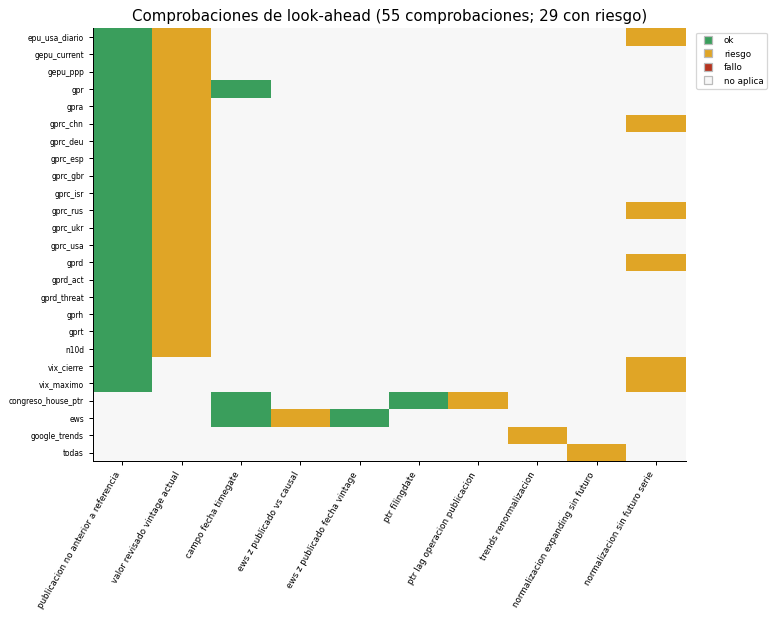

In [10]:
fig, ax = gr.lookahead_semaforo(LA, solo_con_riesgo=True)
plt.show()

### 3.1 EWS: z publicado frente a z causal

El EWS publica un z de actividad recalculado cada vez con **todo** su archivo de un año móvil: el z de un día pasado
cambia cuando llegan datos nuevos (mira el futuro). El z causal se recalcula solo con lo anterior a cada semihora.

**Cómo leerlo.** Si las dos líneas coinciden, el z publicado se podría usar; las diferencias (y el número de alarmas
por encima de cada umbral) miden cuánto engañaría usar el publicado en un backtest.

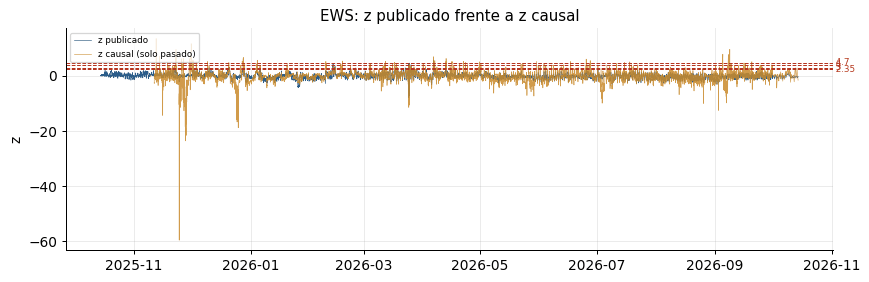

,umbral,n_alarmas_publicado,dias_publicado,n_alarmas_causal,dias_causal,n_alarmas_causal_piso,dias_causal_piso
0,2.35,147,26,740,141,347,79
1,3.00,44,9,452,99,159,38
2,4.00,14,4,196,59,51,13
3,4.70,1,1,107,37,12,3


12991 semihoras: corr 0.60, |dif| media 0.70; alarmas z>=2.0: publicado 275, causal 504. El z publicado se recalcula con el archivo entero (mira el futuro)


In [11]:
AL = T['ews_alarmas']
fig, ax = gr.ews_z(T['ews_z'], umbrales=AL['umbral'].tolist())
plt.show()
display(AL)
print(LA.loc[LA['comprobacion'] == 'ews_z_publicado_vs_causal', 'evidencia'].iloc[0])

### 3.2 Congreso: fecha de operación frente a fecha de publicación

Los representantes tienen 45 días (STOCK Act) para declarar cada operación. Fechar una operación por el día en que se
hizo, y no por el día en que se publicó el PTR, adelantaría información que nadie tenía.

**Cómo leerlo.** A la izquierda, PTR presentados por año (los escaneados exigen OCR). A la derecha, días entre la
operación y su publicación, con el plazo legal: todo lo que queda a la derecha del 0 es retraso que el TimeGate tiene
que respetar.

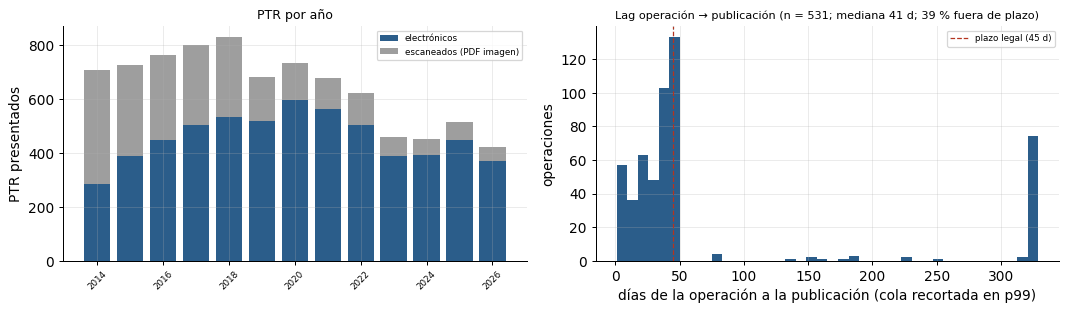

531 operaciones de la muestra: lag operación → publicación mediana 41 d, p90 329 d, máximo 559 d; 38.6 % fuera de plazo.
ptr_filingdate [ok]: 531 operaciones: 0 con publicación anterior a presentación u operación
form4_aceptacion [ok]: 716 transacciones: lag transacción->publicación mediana 4 d, p90 5 d, 73.0 % > 2 d; 0 negativos


In [12]:
OPS = T['congreso_operaciones']
fig, axes = gr.congreso_ptr(T['congreso_ptr_anio'], OPS)
plt.show()
lag_ops = pd.to_numeric(OPS['lag_dias'], errors='coerce').dropna()
print(f'{len(OPS)} operaciones de la muestra: lag operación → publicación mediana {lag_ops.median():.0f} d, '
      f'p90 {lag_ops.quantile(.9):.0f} d, máximo {lag_ops.max():.0f} d; {100 * (lag_ops > 45).mean():.1f} % fuera de plazo.')
for c in ('ptr_filingdate', 'form4_aceptacion'):
    r = LA[LA['comprobacion'] == c].iloc[0]
    print(f'{c} [{r["resultado"]}]: {r["evidencia"]}')

In [13]:
cuenta = LA['resultado'].value_counts()
pub = LA[LA['comprobacion'] == 'publicacion_no_anterior_a_referencia']
z_ok = LA[LA['comprobacion'] == 'normalizacion_expanding_sin_futuro'].iloc[0]
al0 = AL.iloc[0]
print(f'{len(LA)} comprobaciones: ' + ', '.join(f'{k} {cuenta.get(k, 0)}' for k in GRAVEDAD) + '.')
print(f'Series con publicación anterior a la referencia: {int((pub["resultado"] != "ok").sum())} de {len(pub)}.')
print(f'Valores con vintage actual (riesgo): {int((LA["comprobacion"] == "valor_revisado_vintage_actual").sum())} series.')
print(f'z causal [{z_ok["resultado"]}]: {z_ok["evidencia"]}')
for r in LA[LA['comprobacion'] == 'normalizacion_sin_futuro_serie'].itertuples():
    print(f'  {r.fuente}: {r.evidencia}')
print(f'EWS, umbral {al0["umbral"]:g}: alarmas del z publicado {int(al0["n_alarmas_publicado"])} en {int(al0["dias_publicado"])} días '
      f'frente a {int(al0["n_alarmas_causal"])} en {int(al0["dias_causal"])} días con el z causal.')

116 comprobaciones: ok 87, riesgo 29, fallo 0.
Series con publicación anterior a la referencia: 0 de 51.
Valores con vintage actual (riesgo): 19 series.
z causal [riesgo]: pipeline completo rehecho en 3 cortes solo con lo publicado hasta cada corte (rejilla, vigencia, conteos, transformación y z expanding de mínimo 252 obs): 6 de 40 series difieren (máx |dif. z| 5.64): epu_usa_diario, gprc_chn, gprc_rus, gprd, vix_cierre, vix_maximo
  epu_usa_diario: máx |z(hasta t) − z(muestra entera)| = 5.64; 0 días con dato en un pipeline y no en el otro; cortes 1997-07-15, 2010-01-26; transformación nivel con datos hasta 2010-01-26 frente a log con la muestra entera
  gprc_chn: máx |z(hasta t) − z(muestra entera)| = 4.96; 0 días con dato en un pipeline y no en el otro; cortes 1997-07-15, 2022-08-09; transformación log con datos hasta 2022-08-09 frente a nivel con la muestra entera
  gprc_rus: máx |z(hasta t) − z(muestra entera)| = 1.9; 0 días con dato en un pipeline y no en el otro; cortes 1997-07-

## 4. Estudio de eventos alrededor de las crisis de la Fase 1

Para cada crisis cubierta por una serie se toma la trayectoria de su z causal en la ventana del estudio de eventos
(días hábiles, ver parámetros) alrededor del **pico del mercado** (inicio de la ventana pico → suelo del juez de la Fase 1) y se promedia entre crisis.
El intervalo es un t de Student entre crisis (n − 1 grados de libertad) y solo se da con al menos
`validez.CRISIS_BUENA` crisis: con 2-4 crisis un bootstrap percentil apenas tiene medias distintas y subcubre.

**Cómo leerlo.** Línea roja vertical = pico del mercado. Una serie útil para anticipar sube (o baja, si su relación es
inversa) **antes** del día 0; una que solo reacciona se mueve después. El día 0 es el máximo del mercado: la
volatilidad suele estar todavía baja ese día y sube después. Bandas anchas = pocas crisis cubiertas. Se muestra una
serie por fuente (la de más observaciones entre las del apartado 1) con alguna crisis cubierta, y el VIX como referencia.

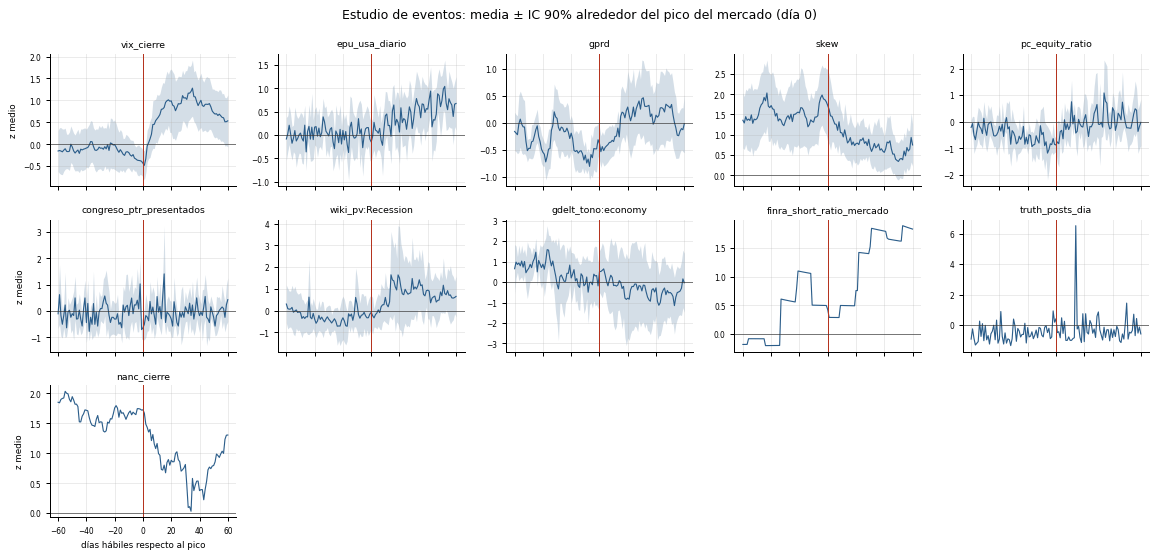

,n_crisis,z_-20,z_0,z_+20,ic_0,dia_0
serie,,,,,,
vix_cierre,12,-0.01,-0.43,0.99,"[-0.74, -0.13]",por debajo de 0
epu_usa_diario,14,0.10,-0.15,0.06,"[-0.58, 0.29]",IC con el 0
gprd,14,-0.19,-0.38,0.30,"[-0.69, -0.07]",por debajo de 0
skew,12,1.54,1.72,0.78,"[0.82, 2.62]",por encima de 0
pc_equity_ratio,5,-0.84,-0.88,0.10,"[-1.13, -0.63]",por debajo de 0
congreso_ptr_presentados,7,-0.30,-0.63,-0.30,"[-1.09, -0.18]",por debajo de 0
wiki_pv:Recession,6,-0.33,-0.08,1.50,"[-0.86, 0.69]",IC con el 0
gdelt_tono:economy,6,0.20,0.51,-0.79,"[-0.51, 1.53]",IC con el 0
finra_short_ratio_mercado,4,1.09,0.42,0.76,—,sin IC (< 5 crisis)


In [14]:
EV = T['validez_eventos']
FUENTE = dict(zip(CAL['serie'], CAL['fuente']))
NOBS = dict(zip(CAL['serie'], CAL['n']))
cubre = set(EV.loc[(EV['dia_rel'] == 0) & (EV['n_crisis'] > 0), 'serie'])
por_fuente = {}
for n in sorted(REPR.values(), key=lambda n: (INICIO[n], n)):
    if n in cubre and (FUENTE[n] not in por_fuente or NOBS[n] > NOBS[por_fuente[FUENTE[n]]]):
        por_fuente[FUENTE[n]] = n
SEL = [va.SERIE_VIX] + [n for n in por_fuente.values() if n != va.SERIE_VIX]
fig, axes = gr.estudio_eventos(EV, series=SEL, ncol=5, nivel_ic=va.NIVEL_IC)
plt.show()

e0 = EV[EV['dia_rel'] == 0].set_index('serie')
piv = EV[EV['serie'].isin(SEL)].pivot_table(index='serie', columns='dia_rel', values='media')
t4 = pd.DataFrame({'n_crisis': e0['n_crisis'], 'z_-20': piv[-20], 'z_0': piv[0], 'z_+20': piv[20],
                   'ic_0': [f'[{a:.2f}, {b:.2f}]' if pd.notna(a) else '—' for a, b in zip(e0['lo'], e0['hi'])]},
                  index=e0.index).reindex(SEL)
lo0, hi0 = e0['lo'].reindex(SEL), e0['hi'].reindex(SEL)
t4['dia_0'] = np.where(t4['n_crisis'] < va.CRISIS_BUENA, f'sin IC (< {va.CRISIS_BUENA} crisis)',
                       np.where(lo0 > 0, 'por encima de 0', np.where(hi0 < 0, 'por debajo de 0', 'IC con el 0')))
display(t4.round(2))

In [15]:
d0 = t4['dia_0'].value_counts()
print(f'{len(SEL)} series en la figura; en el día 0: ' + ', '.join(f'{k} {v}' for k, v in d0.items()) + '.')
for k in ('por encima de 0', 'por debajo de 0'):
    s = t4.index[t4['dia_0'] == k].tolist()
    if s:
        print(f'  {k}: ' + ', '.join(f'{n} (z {t4.loc[n, "z_0"]:.2f}, {int(t4.loc[n, "n_crisis"])} crisis)' for n in s))
ev_ok = e0[e0['n_crisis'] >= va.CRISIS_BUENA]
fuera = ev_ok[(ev_ok['lo'] > 0) | (ev_ok['hi'] < 0)]
print(f'Todas las series: {len(ev_ok)} de {len(e0)} tienen ≥ {va.CRISIS_BUENA} crisis en el día 0 y {len(fuera)} de ellas un IC '
      f'que excluye el 0; por azar se esperarían ≈ {(1 - va.NIVEL_IC) * len(ev_ok):.1f} (IC al {va.NIVEL_IC:.0%}, sin '
      'corregir por comparaciones múltiples).')
sube = t4[(t4['z_-20'].abs() > t4['z_0'].abs()) & t4['n_crisis'].ge(va.CRISIS_BUENA)]
print(f'Con |z| ya mayor 20 días antes del pico que en el pico (≥ {va.CRISIS_BUENA} crisis): '
      + (', '.join(sube.index) or 'ninguna'))

11 series en la figura; en el día 0: por debajo de 0 4, IC con el 0 3, sin IC (< 5 crisis) 3, por encima de 0 1.
  por encima de 0: skew (z 1.72, 12 crisis)
  por debajo de 0: vix_cierre (z -0.43, 12 crisis), gprd (z -0.38, 14 crisis), pc_equity_ratio (z -0.88, 5 crisis), congreso_ptr_presentados (z -0.63, 7 crisis)
Todas las series: 39 de 44 tienen ≥ 5 crisis en el día 0 y 18 de ellas un IC que excluye el 0; por azar se esperarían ≈ 3.9 (IC al 90%, sin corregir por comparaciones múltiples).
Con |z| ya mayor 20 días antes del pico que en el pico (≥ 5 crisis): wiki_pv:Recession


## 5. ¿Separa crisis de no crisis? AUC frente al VIX

AUC de Mann-Whitney del z causal: probabilidad de que un día de crisis tenga un z mayor que uno sin crisis
(0,5 = azar; por debajo de 0,5, relación inversa). La etiqueta se adelanta según los adelantos de la tabla de parámetros: con un adelanto h,
el z de hoy se compara con «habrá crisis dentro de h días hábiles». La comparación con el VIX va siempre en los **mismos
días**: `auc_mismo_periodo` (la serie) y `auc_vix_mismo_periodo` (el VIX) usan solo los días con las dos series. El
`auc` de todos los días de la serie (que en GPR y EPU incluye 1985-1989, antes del VIX) queda solo como dato descriptivo.
El intervalo (`auc_lo`, `auc_hi`) remuestrea crisis completas: su n efectivo es el número de crisis.

**Cómo leerlo.** Barra verde: supera al VIX de los mismos días; gris: no lo supera, aunque esté lejos de 0,5. Que un
AUC < 0,5 cuente como señal depende del signo esperado de la serie (tabla de parámetros): sí en el tono de las
noticias, no en un índice de incertidumbre.

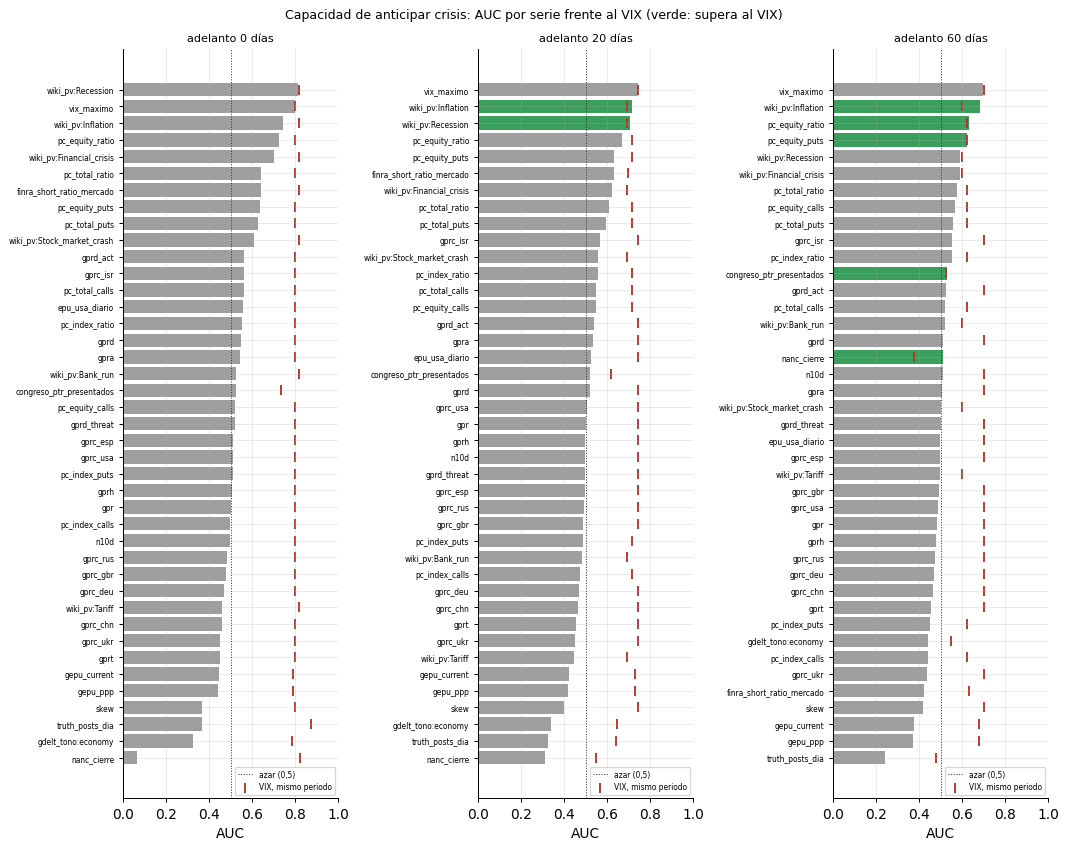

In [16]:
fig, axes = gr.auc_vs_vix(AUC, auc='auc_mismo_periodo')
plt.show()

**Cómo leerlo.** Izquierda: crisis de la Fase 1 que cubre cada serie (verde ≥ umbral de historia del semáforo).
Derecha: distancia a 0,5 de la serie menos la del VIX en los mismos días, con adelanto 0 (descriptivo: una relación
inversa cuenta igual que una directa; el semáforo solo cuenta el sentido esperado). A la derecha del 0, la serie separa crisis mejor que el VIX. Las series con pocas crisis
tienen AUC muy ruidosos: la izquierda dice cuánto fiarse de la derecha.

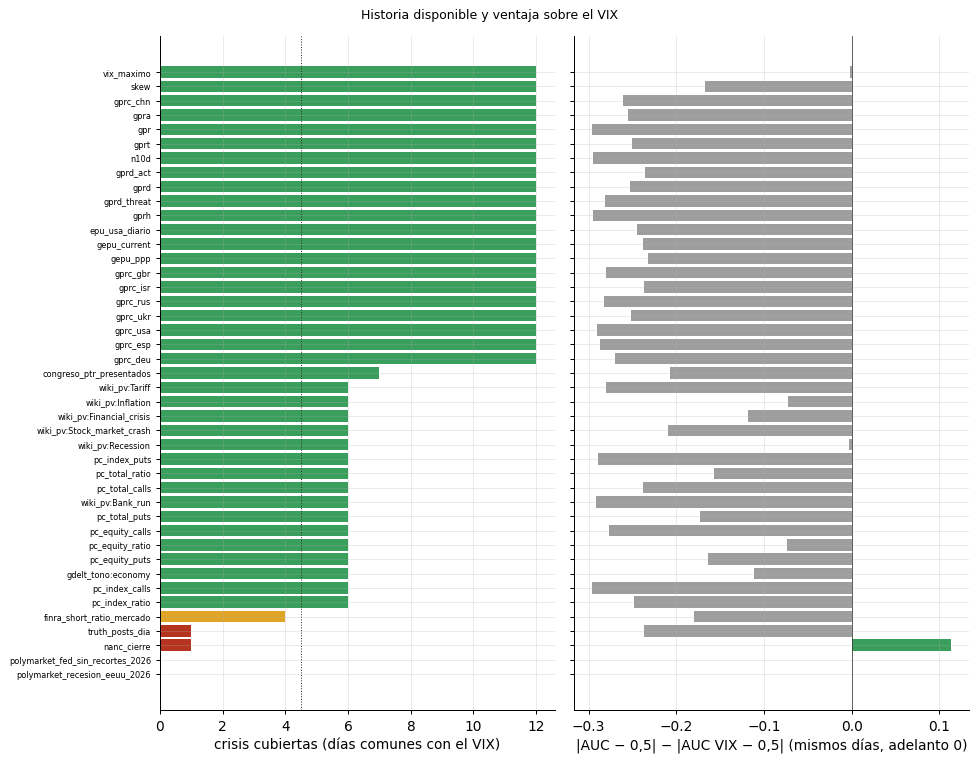

,adelanto,serie,auc_mismo_periodo,auc_lo,auc_hi,auc_vix_mismo_periodo,auc,n_crisis_mismo_periodo
0,0,wiki_pv:Financial_crisis,0.6999,0.5848,0.7933,0.8178,0.6999,6
1,0,pc_equity_ratio,0.7250,0.6494,0.7649,0.7988,0.7250,6
2,0,wiki_pv:Inflation,0.7446,0.5658,0.7954,0.8178,0.7446,6
3,0,vix_maximo,0.7977,0.7048,0.8576,0.7999,0.7977,12
4,0,wiki_pv:Recession,0.8150,0.6775,0.8616,0.8178,0.8150,6
5,20,gdelt_tono:economy,0.3398,0.2974,0.4377,0.6434,0.3398,6
6,20,pc_equity_ratio,0.6681,0.5283,0.7188,0.7129,0.6681,6
7,20,wiki_pv:Recession,0.7071,0.5121,0.7657,0.6940,0.7071,6
8,20,wiki_pv:Inflation,0.7167,0.5432,0.7747,0.6940,0.7167,6
9,20,vix_maximo,0.7412,0.6119,0.8040,0.7433,0.7412,12


In [17]:
a0 = AUC[AUC['adelanto'] == 0].set_index('serie')
a0 = a0[a0.index != va.SERIE_VIX].sort_values('n_crisis_mismo_periodo')
fig, axes = plt.subplots(1, 2, figsize=(11, 0.17 * len(a0) + 1.3), sharey=True)
col_n = [gr.C_ESTADO['ok'] if v >= va.CRISIS_BUENA else (gr.C_ESTADO['parcial'] if v >= va.CRISIS_REGULAR
         else gr.C_ESTADO['fallo']) for v in a0['n_crisis_mismo_periodo']]
axes[0].barh(a0.index, a0['n_crisis_mismo_periodo'], color=col_n)
axes[0].axvline(va.CRISIS_BUENA - 0.5, color='#333333', ls=':', lw=0.8)
axes[0].set_xlabel('crisis cubiertas (días comunes con el VIX)')
axes[0].tick_params(axis='y', labelsize=6.5)
dif = (a0['auc_mismo_periodo'] - 0.5).abs() - (a0['auc_vix_mismo_periodo'] - 0.5).abs()
axes[1].barh(a0.index, dif, color=[gr.C_ESTADO['ok'] if v > 0 else gr.C_GRIS for v in dif])
axes[1].axvline(0, color='#333333', lw=0.6)
axes[1].set_xlabel('|AUC − 0,5| − |AUC VIX − 0,5| (mismos días, adelanto 0)')
fig.suptitle('Historia disponible y ventaja sobre el VIX', fontsize=10)
fig.tight_layout()
plt.show()

top = (AUC[(AUC['serie'] != va.SERIE_VIX) & (AUC['n_crisis_mismo_periodo'] >= va.CRISIS_REGULAR)]
       .assign(dist=lambda d: (d['auc_mismo_periodo'] - 0.5).abs())
       .sort_values('dist', ascending=False).groupby('adelanto').head(5)
       [['adelanto', 'serie', 'auc_mismo_periodo', 'auc_lo', 'auc_hi', 'auc_vix_mismo_periodo', 'auc',
         'n_crisis_mismo_periodo']].sort_values(['adelanto', 'auc_mismo_periodo']))
display(top.reset_index(drop=True))

In [18]:
vix = AUC[AUC['serie'] == va.SERIE_VIX].set_index('adelanto')
otras = AUC[~AUC['serie'].isin(va.SERIES_REFERENCIA)]
print('VIX: ' + ', '.join(f'AUC {r.auc:.3f} [{r.auc_lo:.3f}, {r.auc_hi:.3f}] con adelanto {h} ({int(r.n_crisis)} crisis)'
                          for h, r in vix.iterrows()) + '.')
print(f'(En la tabla, solo series con ≥ {va.CRISIS_REGULAR} crisis en los días comunes; en «la más lejos de 0,5», con '
      f'≥ {va.CRISIS_BUENA}: con menos, el AUC lo decide una sola crisis.)')
for h, g in otras.groupby('adelanto'):
    g = g.dropna(subset=['auc_mismo_periodo'])
    gb = g[g['n_crisis_mismo_periodo'] >= va.CRISIS_BUENA]
    mejor = gb.loc[(gb['auc_mismo_periodo'] - 0.5).abs().idxmax()]
    ic_sin = int(((g['auc_lo'] > 0.5) | (g['auc_hi'] < 0.5)).sum())
    print(f'Adelanto {h}: {int((g["auc_mismo_periodo"] > g["auc_vix_mismo_periodo"]).sum())} de {len(g)} series superan al '
          f'VIX en los mismos días; {int(((g["auc_mismo_periodo"] - 0.5).abs() >= va.AUC_BUENA).sum())} con |AUC − 0,5| ≥ '
          f'{va.AUC_BUENA:g}; {ic_sin} con IC por bloques sin el 0,5; la más lejos de 0,5: {mejor["serie"]} '
          f'{mejor["auc_mismo_periodo"]:.3f} (VIX {mejor["auc_vix_mismo_periodo"]:.3f}).')
cambia = otras[otras['adelanto'] == 0].assign(d=lambda d: (d['auc'] - d['auc_mismo_periodo']).abs())
cambia = cambia[cambia['n_dias'] > cambia['n_dias_mismo_periodo']]
print(f'Series con días fuera del periodo del VIX: {len(cambia)}; |AUC(todos los días) − AUC(días del VIX)| mediano '
      f'{cambia["d"].median():.3f}, máximo {cambia["d"].max():.3f} ({cambia.loc[cambia["d"].idxmax(), "serie"]}).')
print(f'Comparaciones hechas: {otras["serie"].nunique()} series × {otras["adelanto"].nunique()} adelantos = '
      f'{len(otras)} AUC; a un 10 % de falsos positivos (IC al {va.NIVEL_IC:.0%}) se esperarían unos '
      f'{(1 - va.NIVEL_IC) * len(otras):.0f} IC sin el 0,5 por azar.')

VIX: AUC 0.800 [0.706, 0.859] con adelanto 0 (12 crisis), AUC 0.743 [0.609, 0.806] con adelanto 20 (12 crisis), AUC 0.699 [0.538, 0.767] con adelanto 60 (12 crisis).
(En la tabla, solo series con ≥ 2 crisis en los días comunes; en «la más lejos de 0,5», con ≥ 5: con menos, el AUC lo decide una sola crisis.)
Adelanto 0: 0 de 40 series superan al VIX en los mismos días; 6 con |AUC − 0,5| ≥ 0.15; 7 con IC por bloques sin el 0,5; la más lejos de 0,5: wiki_pv:Recession 0.815 (VIX 0.818).
Adelanto 20: 2 de 40 series superan al VIX en los mismos días; 6 con |AUC − 0,5| ≥ 0.15; 7 con IC por bloques sin el 0,5; la más lejos de 0,5: wiki_pv:Inflation 0.717 (VIX 0.694).
Adelanto 60: 5 de 40 series superan al VIX en los mismos días; 2 con |AUC − 0,5| ≥ 0.15; 3 con IC por bloques sin el 0,5; la más lejos de 0,5: wiki_pv:Inflation 0.683 (VIX 0.598).
Series con días fuera del periodo del VIX: 17; |AUC(todos los días) − AUC(días del VIX)| mediano 0.016, máximo 0.043 (gprc_gbr).
Comparaciones hechas: 4

## 6. Adelantos y retrasos (lead-lag)

Correlación entre la serie hoy y la referencia `lag` días hábiles después, para los lags de `validez.LAGS`, frente
al VIX y al drawdown del S&P 500, en cambios a 5 días (`cambio_5d`, para no correlacionar tendencias) y en nivel del
z causal (`nivel_z`). Se calcula en **dos rejillas**, porque mezclan cosas distintas:

- **por fecha de referencia** (`_ref`): cada dato en el día al que se refiere. Mide el **contenido**: qué serie se
  mueve antes;
- **por fecha de publicación** (`_pub`, la rejilla del TimeGate): mide lo **utilizable**: qué se sabe antes. Aquí el
  retraso de publicación desplaza la serie (tono de GDELT ≈ 5 días, VIX y Wikipedia D+1) y el drawdown sigue la misma
  convención que el VIX (el cierre de D se usa desde D+1).

El lag de máxima |correlación| solo se da si se distingue del lag 0: `lag_max` queda **indeterminado** si
|corr_max| − |corr_lag0| < 2/√n_eff, con n_eff = n/5 en `cambio_5d` (ventanas solapadas) y la aproximación de Bartlett
para dos AR(1) en `nivel_z` (niveles muy persistentes: n_eff pequeño). `lag_max_bruto` guarda el máximo sin filtro.

**Cómo leerlo.** Rojo = correlación positiva, azul = negativa; el punto negro marca el lag de máxima |correlación|
(bruto). Si cae a la derecha del 0, la serie se adelanta a la referencia; a la izquierda, va por detrás. Las dos
primeras figuras son la misma comparación con el VIX en las dos rejillas: lo que se desplaza de una a otra es retraso
de publicación, no contenido. La tercera es el drawdown por fecha de referencia.

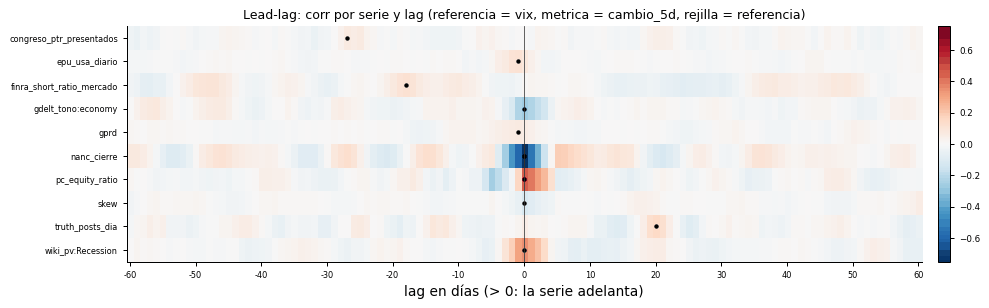

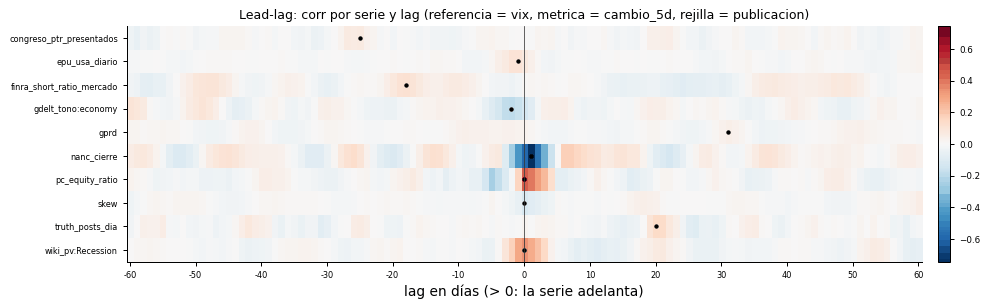

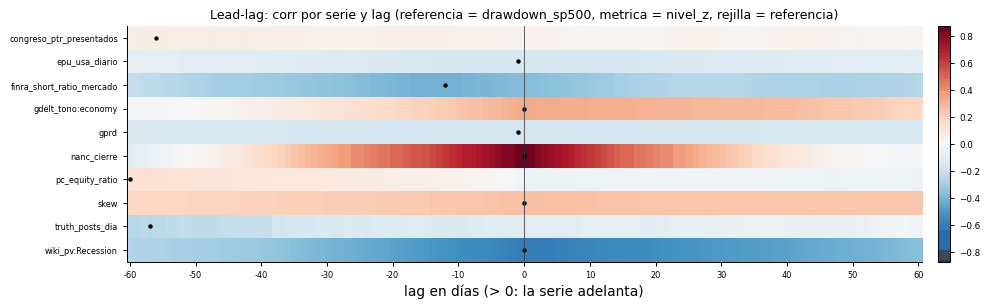

In [19]:
LL = T['validez_leadlag']
LLR = T['validez_leadlag_resumen']
SEL6 = [s for s in SEL if s != va.SERIE_VIX]
for filtro in ({'referencia': 'vix', 'metrica': 'cambio_5d', 'rejilla': 'referencia'},
               {'referencia': 'vix', 'metrica': 'cambio_5d', 'rejilla': 'publicacion'},
               {'referencia': 'drawdown_sp500', 'metrica': 'nivel_z', 'rejilla': 'referencia'}):
    fig, ax = gr.calor_lead_lag(LL[LL['serie'].isin(SEL6)], filtro=filtro)
    plt.show()

In [20]:
def lado(lag) -> str:
    if pd.isna(lag):
        return 'indeterminado'
    return 'la serie adelanta' if lag > 0 else ('la serie va detrás' if lag < 0 else 'simultánea')


for ref, met in (('vix', 'cambio_5d'), ('vix', 'nivel_z'), ('drawdown_sp500', 'cambio_5d'), ('drawdown_sp500', 'nivel_z')):
    r = LLR[(LLR['referencia'] == ref) & (LLR['metrica'] == met)]
    partes = []
    for g, nombre in (('ref', 'por referencia'), ('pub', 'por publicación')):
        c = r[f'lag_max_{g}'].map(lado).value_counts()
        partes.append(f'{nombre}: ' + ', '.join(f'{k} {v}' for k, v in c.items()))
    print(f'{ref} · {met} ({len(r)} series) · ' + ' | '.join(partes))
COLS_LL = ['serie', 'referencia', 'metrica', 'lag_pub_serie_d', 'lag_max_ref', 'lag_max_bruto_ref', 'corr_max_ref',
           'corr_lag0_ref', 'margen_ref', 'lag_max_pub', 'lag_max_bruto_pub', 'corr_max_pub', 'corr_lag0_pub', 'margen_pub']
det = LLR[LLR['serie'].isin(SEL6) & (LLR['lag_max_ref'].fillna(0).ne(0) | LLR['lag_max_pub'].fillna(0).ne(0))]
print(f'Series de la figura con algún lag distinto de 0 e identificado ({len(det)} filas):')
display(det[COLS_LL].reset_index(drop=True))
gd = LLR[(LLR['serie'] == 'gdelt_tono:economy') & (LLR['referencia'] == 'vix')].set_index('metrica')
display(gd.reset_index()[COLS_LL])
fmt = lambda v: 'indeterminado' if pd.isna(v) else f'{int(v):+d}'
for met in ('cambio_5d', 'nivel_z'):
    r = gd.loc[met]
    print(f'gdelt_tono:economy frente al VIX ({met}): por referencia, lag {fmt(r["lag_max_ref"])} '
          f'(corr {r["corr_max_ref"]:+.3f}; en lag 0 {r["corr_lag0_ref"]:+.3f}); por publicación, lag {fmt(r["lag_max_pub"])} '
          f'(máximo bruto en {int(r["lag_max_bruto_pub"]):+d}, corr {r["corr_max_pub"]:+.3f} frente a {r["corr_lag0_pub"]:+.3f} en '
          f'lag 0; margen {r["margen_pub"]:.3f}). Retraso mediano de publicación: {r["lag_pub_serie_d"]:g} d el tono, '
          f'{r["lag_pub_referencia_d"]:g} d el VIX.')

vix · cambio_5d (43 series) · por referencia: indeterminado 21, simultánea 18, la serie va detrás 2, la serie adelanta 2 | por publicación: indeterminado 20, simultánea 15, la serie va detrás 6, la serie adelanta 2
vix · nivel_z (43 series) · por referencia: indeterminado 25, simultánea 13, la serie va detrás 4, la serie adelanta 1 | por publicación: indeterminado 28, simultánea 11, la serie va detrás 4
drawdown_sp500 · cambio_5d (44 series) · por referencia: indeterminado 24, simultánea 19, la serie va detrás 1 | por publicación: indeterminado 25, simultánea 15, la serie adelanta 3, la serie va detrás 1
drawdown_sp500 · nivel_z (44 series) · por referencia: indeterminado 31, simultánea 8, la serie va detrás 5 | por publicación: indeterminado 35, simultánea 5, la serie va detrás 4
Series de la figura con algún lag distinto de 0 e identificado (8 filas):


,serie,referencia,metrica,lag_pub_serie_d,lag_max_ref,lag_max_bruto_ref,corr_max_ref,corr_lag0_ref,margen_ref,lag_max_pub,lag_max_bruto_pub,corr_max_pub,corr_lag0_pub,margen_pub
0,congreso_ptr_presentados,vix,nivel_z,1.0,-56.0,-56.0,-0.0616,-0.0196,0.0412,NaN,-50.0,-0.0595,-0.0271,0.0401
1,finra_short_ratio_mercado,vix,cambio_5d,1.0,-18.0,-18.0,0.1118,0.0094,0.0968,-18.0,-18.0,0.1115,0.0067,0.0968
2,gdelt_tono:economy,drawdown_sp500,cambio_5d,5.0,0.0,0.0,0.2300,0.2300,0.0888,-2.0,-2.0,0.1929,0.0932,0.0889
3,nanc_cierre,vix,cambio_5d,0.0,0.0,0.0,-0.7520,-0.7520,0.1446,1.0,1.0,-0.7441,-0.5836,0.1446
4,nanc_cierre,drawdown_sp500,cambio_5d,0.0,0.0,0.0,0.9088,0.9088,0.1446,1.0,1.0,0.9090,0.7143,0.1446
5,pc_equity_ratio,drawdown_sp500,nivel_z,1.0,-60.0,-60.0,0.1269,-0.0533,0.0686,NaN,-60.0,0.1171,-0.0607,0.0687
6,truth_posts_dia,vix,nivel_z,1.0,-31.0,-31.0,-0.2499,-0.1529,0.0963,-31.0,-31.0,-0.2553,-0.1554,0.0952
7,truth_posts_dia,drawdown_sp500,nivel_z,1.0,-57.0,-57.0,-0.2415,-0.1120,0.0975,-58.0,-58.0,-0.2109,-0.1079,0.0962


,serie,referencia,metrica,lag_pub_serie_d,lag_max_ref,lag_max_bruto_ref,corr_max_ref,corr_lag0_ref,margen_ref,lag_max_pub,lag_max_bruto_pub,corr_max_pub,corr_lag0_pub,margen_pub
0,gdelt_tono:economy,vix,cambio_5d,5.0,0.0,0.0,-0.2639,-0.2639,0.0888,NaN,-2.0,-0.1916,-0.1221,0.0889
1,gdelt_tono:economy,vix,nivel_z,5.0,0.0,0.0,-0.4842,-0.4842,0.1486,NaN,-2.0,-0.4777,-0.4645,0.1364


gdelt_tono:economy frente al VIX (cambio_5d): por referencia, lag +0 (corr -0.264; en lag 0 -0.264); por publicación, lag indeterminado (máximo bruto en -2, corr -0.192 frente a -0.122 en lag 0; margen 0.089). Retraso mediano de publicación: 5 d el tono, 1 d el VIX.
gdelt_tono:economy frente al VIX (nivel_z): por referencia, lag +0 (corr -0.484; en lag 0 -0.484); por publicación, lag indeterminado (máximo bruto en -2, corr -0.478 frente a -0.465 en lag 0; margen 0.136). Retraso mediano de publicación: 5 d el tono, 1 d el VIX.


## 7. Estabilidad por subperiodos

AUC (adelanto 0) en cada década y antes/después del corte, solo en los subperiodos con días de crisis y sin crisis,
en los días comunes con el VIX (`auc_mismo_periodo`, comparable con `auc_vix`).
Una señal que solo funciona en una década es probablemente un accidente de esa década.

**Cómo leerlo.** En la matriz, verde = AUC por encima de 0,5, rojo = por debajo, amarillo ≈ azar. En el diagrama de
dispersión, cada punto es una serie: sobre la diagonal, la señal se mantiene; si cruza la línea de 0,5, cambia de signo.

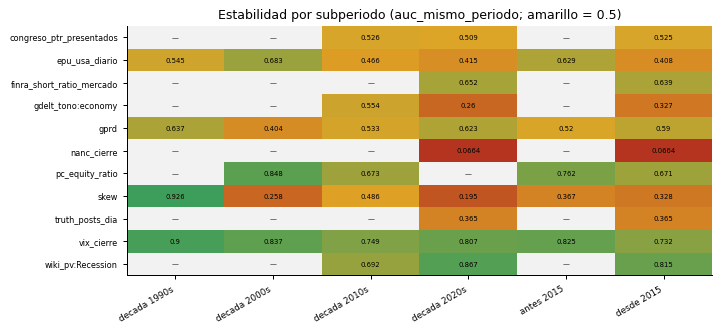

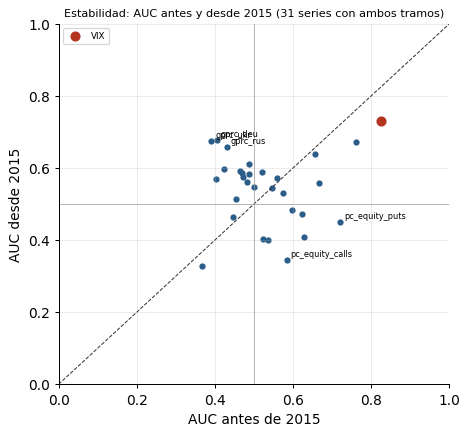

In [21]:
EST = T['validez_estabilidad']
fig, ax = gr.estabilidad_subperiodos(EST[EST['serie'].isin(SEL)], como='calor', valor='auc_mismo_periodo')
plt.show()

c = va.CORTE_ESTABILIDAD
AB = EST.pivot_table(index='serie', columns='periodo', values='auc_mismo_periodo')[[f'antes_{c}', f'desde_{c}']].dropna()
cambio = (AB[f'desde_{c}'] - AB[f'antes_{c}'])
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.scatter(AB[f'antes_{c}'], AB[f'desde_{c}'], s=16, color=gr.C_BASE)
if va.SERIE_VIX in AB.index:
    ax.scatter(*AB.loc[va.SERIE_VIX], s=50, color=gr.C_CRISIS, label='VIX', zorder=3)
for n in cambio.abs().sort_values(ascending=False).head(5).index:
    ax.annotate(n, AB.loc[n], fontsize=6.5, xytext=(3, 3), textcoords='offset points')
ax.plot([0, 1], [0, 1], color='#333333', ls='--', lw=0.8)
ax.axhline(0.5, color=gr.C_GRIS, lw=0.6)
ax.axvline(0.5, color=gr.C_GRIS, lw=0.6)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel(f'AUC antes de {c}')
ax.set_ylabel(f'AUC desde {c}')
ax.legend(fontsize=7)
ax.set_title(f'Estabilidad: AUC antes y desde {c} ({len(AB)} series con ambos tramos)', fontsize=9)
plt.show()

In [22]:
signo = ((AB[f'antes_{c}'] - 0.5) * (AB[f'desde_{c}'] - 0.5) < 0)
if va.SERIE_VIX in AB.index:
    print(f'VIX: AUC {AB.loc[va.SERIE_VIX, f"antes_{c}"]:.3f} antes de {c} y {AB.loc[va.SERIE_VIX, f"desde_{c}"]:.3f} desde {c}.')
print(f'{len(AB)} series con los dos tramos; cambian de signo (cruzan 0,5): {int(signo.sum())}; '
      f'cambio mediano |ΔAUC| {cambio.abs().median():.3f}; mayor cambio: {cambio.abs().idxmax()} ({cambio[cambio.abs().idxmax()]:+.3f}).')
print(f'Series que solo existen desde {c} (sin tramo previo): '
      f'{EST.loc[EST["periodo"] == f"desde_{c}", "serie"].nunique() - len(AB)}.')

VIX: AUC 0.825 antes de 2015 y 0.732 desde 2015.
31 series con los dos tramos; cambian de signo (cruzan 0,5): 19; cambio mediano |ΔAUC| 0.109; mayor cambio: gprc_ukr (+0.285).
Series que solo existen desde 2015 (sin tramo previo): 11.


## 8. Calibración de Polymarket y Kalshi

Mercados ya resueltos de la sonda: la probabilidad implícita unos días antes del cierre (horizontes de la tabla) frente a lo que pasó.

- **Brier**: error cuadrático medio de la probabilidad (0 perfecto). El **climatológico** es el Brier de predecir
  siempre la frecuencia base, p(1 − p): ganarle es el mínimo exigible.
- **Descomposición de Murphy**: Brier ≈ fiabilidad − resolución + incertidumbre. Fiabilidad baja = probabilidades
  honestas; resolución alta = distingue bien unos mercados de otros.
- **Mercados indecisos**: los que a ese horizonte cotizan entre los límites de `validez.PROB_INDECISA`. Fuera de
  ese rango el mercado ya está decidido (a 1 d hay mercados cuyo hecho ya ocurrió y aún no se ha liquidado: el precio
  se toma respecto al cierre del mercado) y gana al climatológico sin informar. **La cifra principal es la de los
  indecisos**; `n_decididos` cuenta los demás y `bss` = 1 − Brier/climatológico.
- **Liquidez**: los mercados se parten por la mediana del volumen **final** de cada plataforma, que solo se conoce
  ex post: es una partición descriptiva, no una regla que un agente pudiera aplicar.

**Cómo leerlo.** En el diagrama de fiabilidad, un mercado calibrado está sobre la diagonal (lo que dice el 30 % pasa
el 30 % de las veces); el tamaño del punto es el número de mercados del tramo. En las barras, cuanto más baja la barra
frente a su raya negra (climatológico), más informa el mercado.

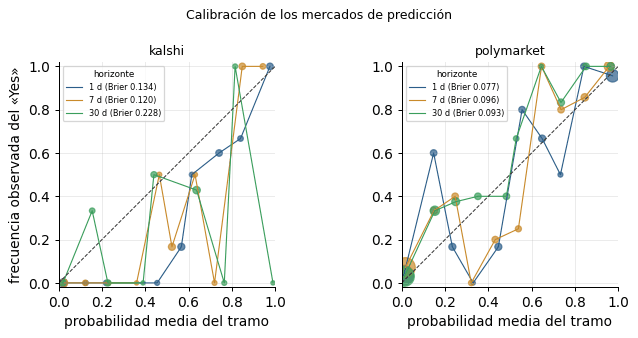

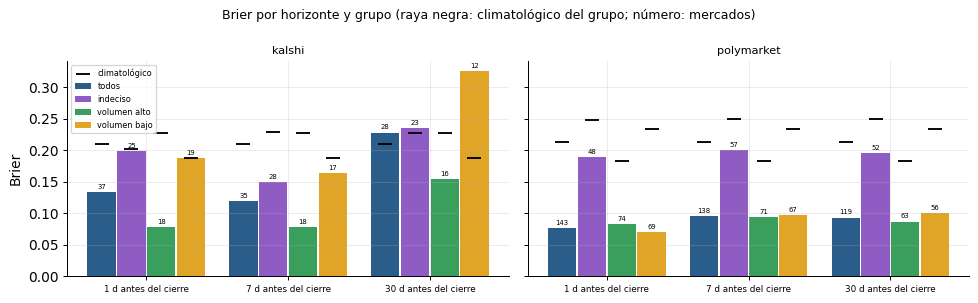

,plataforma,horizonte_dias,liquidez,umbral_volumen_usd,n,brier,fiabilidad,resolucion,incertidumbre,brier_clima,frec_yes,n_decididos,bss
0,kalshi,1,todos,156044.00,37,0.134,0.048,0.133,0.219,0.210,0.300,12,0.360
1,kalshi,1,volumen_alto,156044.00,18,0.078,0.078,0.238,0.238,0.228,0.350,10,0.656
2,kalshi,1,volumen_bajo,156044.00,19,0.187,0.077,0.086,0.194,0.188,0.250,2,0.001
3,kalshi,1,indeciso,156044.00,25,0.199,0.071,0.074,0.202,0.202,0.280,0,0.015
4,kalshi,7,todos,156044.00,35,0.120,0.066,0.163,0.216,0.210,0.300,7,0.429
5,kalshi,7,volumen_alto,156044.00,18,0.078,0.078,0.238,0.238,0.228,0.350,5,0.657
6,kalshi,7,volumen_bajo,156044.00,17,0.164,0.115,0.133,0.180,0.188,0.250,2,0.124
7,kalshi,7,indeciso,156044.00,28,0.150,0.082,0.164,0.230,0.230,0.357,0,0.347
8,kalshi,30,todos,156044.00,28,0.228,0.107,0.083,0.204,0.210,0.300,5,-0.086
9,kalshi,30,volumen_alto,156044.00,16,0.155,0.053,0.128,0.234,0.228,0.350,3,0.318


In [23]:
CALB = T['validez_calibracion']
fig, axes = gr.fiabilidad_calibracion(T['validez_fiabilidad_bins'], CALB)
plt.show()

LIQ = {'todos': gr.C_BASE, 'indeciso': '#8e5cc2', 'volumen_alto': '#3a9e5c', 'volumen_bajo': '#e0a526'}
plats = sorted(CALB['plataforma'].unique())
fig, axes = plt.subplots(1, len(plats), figsize=(11, 3.4), sharey=True, squeeze=False)
for ax, pl in zip(axes[0], plats):
    g = CALB[CALB['plataforma'] == pl]
    hs = sorted(g['horizonte_dias'].unique())
    for j, (lq, color) in enumerate(LIQ.items()):
        t = g[g['liquidez'] == lq].set_index('horizonte_dias').reindex(hs)
        x = np.arange(len(hs)) + (j - 1.5) * 0.21
        ax.bar(x, t['brier'], width=0.2, color=color, label=lq.replace('_', ' '))
        ax.scatter(x, t['brier_clima'], marker='_', s=140, color='black', zorder=3,
                   label='climatológico' if j == 0 else None)
        for xi, b, n in zip(x, t['brier'], t['n']):
            if pd.notna(b):
                ax.text(xi, b + 0.005, f'{int(n)}', ha='center', fontsize=5.5)
    ax.set_xticks(range(len(hs)))
    ax.set_xticklabels([f'{h} d antes del cierre' for h in hs], fontsize=7)
    ax.set_title(pl, fontsize=9)
axes[0, 0].set_ylabel('Brier')
axes[0, 0].legend(fontsize=6.5, loc='upper left')
fig.suptitle('Brier por horizonte y grupo (raya negra: climatológico del grupo; número: mercados)', fontsize=10)
fig.tight_layout()
plt.show()
display(CALB.round(3))

In [24]:
for pl, g in CALB.groupby('plataforma'):
    for h in sorted(g['horizonte_dias'].unique()):
        i = g[(g['horizonte_dias'] == h) & (g['liquidez'] == 'indeciso')].iloc[0]
        t = g[(g['horizonte_dias'] == h) & (g['liquidez'] == 'todos')].iloc[0]
        print(f'{pl} a {h} d · indecisos: Brier {i["brier"]:.3f} frente a {i["brier_clima"]:.3f} climatológico '
              f'(BSS {i["bss"]:+.0%}, n={int(i["n"])}) · todos: {t["brier"]:.3f} frente a {t["brier_clima"]:.3f} '
              f'(BSS {t["bss"]:+.0%}, n={int(t["n"])}, {int(t["n_decididos"])} ya decididos)')
    a = g[(g['horizonte_dias'] == 7) & (g['liquidez'] == 'volumen_alto')].iloc[0]
    b = g[(g['horizonte_dias'] == 7) & (g['liquidez'] == 'volumen_bajo')].iloc[0]
    print(f'  {pl} a 7 d por volumen final (ex post; umbral {a["umbral_volumen_usd"]:,.0f} USD): alto {a["brier"]:.3f} '
          f'(n={int(a["n"])}) frente a bajo {b["brier"]:.3f} (n={int(b["n"])})')

kalshi a 1 d · indecisos: Brier 0.199 frente a 0.202 climatológico (BSS +1%, n=25) · todos: 0.134 frente a 0.210 (BSS +36%, n=37, 12 ya decididos)
kalshi a 7 d · indecisos: Brier 0.150 frente a 0.230 climatológico (BSS +35%, n=28) · todos: 0.120 frente a 0.210 (BSS +43%, n=35, 7 ya decididos)
kalshi a 30 d · indecisos: Brier 0.235 frente a 0.227 climatológico (BSS -4%, n=23) · todos: 0.228 frente a 0.210 (BSS -9%, n=28, 5 ya decididos)
  kalshi a 7 d por volumen final (ex post; umbral 156,044 USD): alto 0.078 (n=18) frente a bajo 0.164 (n=17)
polymarket a 1 d · indecisos: Brier 0.190 frente a 0.248 climatológico (BSS +24%, n=48) · todos: 0.077 frente a 0.213 (BSS +64%, n=143, 95 ya decididos)
polymarket a 7 d · indecisos: Brier 0.200 frente a 0.249 climatológico (BSS +20%, n=57) · todos: 0.096 frente a 0.213 (BSS +55%, n=138, 81 ya decididos)
polymarket a 30 d · indecisos: Brier 0.196 frente a 0.250 climatológico (BSS +22%, n=52) · todos: 0.093 frente a 0.213 (BSS +56%, n=119, 67 ya de

## 9. Rentabilidad anormal: Congreso e insiders

CAR ajustado por mercado (rentabilidad del valor menos la del SPY) a los horizontes de `validez.HORIZONTES_CAR` (sesiones) tras cada compra, entrando
al cierre de la primera sesión en o después de la fecha. Se calcula dos veces:

- **desde la publicación** (PTR presentado o Form 4 aceptado): lo que un agente podría haber hecho;
- **desde la operación**: lo que se vería si se fechara mal (look-ahead). La diferencia mide cuánto engaña.

> **Aviso de potencia.** Los eventos son pocos (muestra de la sonda) y varios coinciden en el tiempo: el intervalo
> remuestrea **semanas completas** (los eventos de una semana comparten mercado y las ventanas se solapan). Es una
> ilustración del efecto de fechar bien, no una estrategia.
>
> **Supervivencia.** yfinance no da precio de los valores deslistados: si falta precio en más del
> `validez.MAX_SIN_PRECIO` de los eventos, la muestra con precio está sesgada hacia las empresas que sobrevivieron y el
> grupo se marca **no evaluable** (no entra en el semáforo).

**Cómo leerlo.** Azul: desde la publicación; naranja: desde la operación. Un intervalo que cruza el 0 no permite
afirmar nada; un grupo marcado «no evaluable» en el título no se lee. En la dispersión, sobre la diagonal el CAR
desde la publicación coincide con el de la operación.

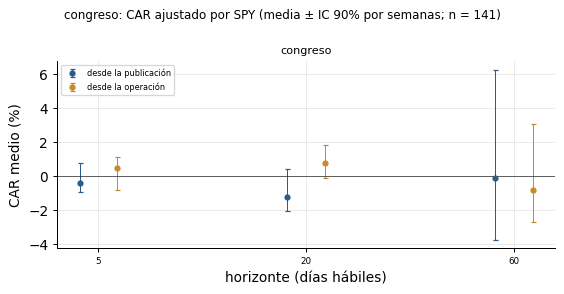

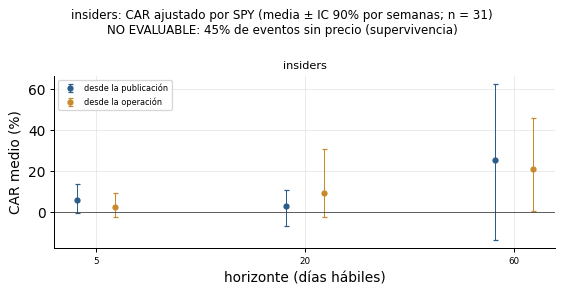

,grupo,referencia_fecha,horizonte,n,car_medio_%,lo_%,hi_%,pct_positivos,n_eventos,n_sin_precio,pct_sin_precio,n_semanas,evaluable
0,congreso,publicacion,5,141,-0.43,-0.97,0.76,39.7163,152,10,0.0658,22,True
1,congreso,publicacion,20,141,-1.24,-2.08,0.39,35.4610,152,10,0.0658,22,True
2,congreso,publicacion,60,141,-0.13,-3.76,6.29,43.9716,152,10,0.0658,22,True
3,congreso,operacion,5,141,0.45,-0.80,1.14,55.3191,152,10,0.0658,33,True
4,congreso,operacion,20,141,0.80,-0.11,1.84,50.3546,152,10,0.0658,33,True
5,congreso,operacion,60,141,-0.83,-2.73,3.08,44.6809,152,10,0.0658,33,True
6,insiders,publicacion,5,30,6.08,-0.35,14.01,60.0000,60,27,0.4500,7,False
7,insiders,publicacion,20,30,2.98,-6.52,10.79,46.6667,60,27,0.4500,7,False
8,insiders,publicacion,60,30,25.56,-13.61,62.47,43.3333,60,27,0.4500,7,False
9,insiders,operacion,5,31,2.67,-2.21,9.47,51.6129,60,27,0.4500,12,False


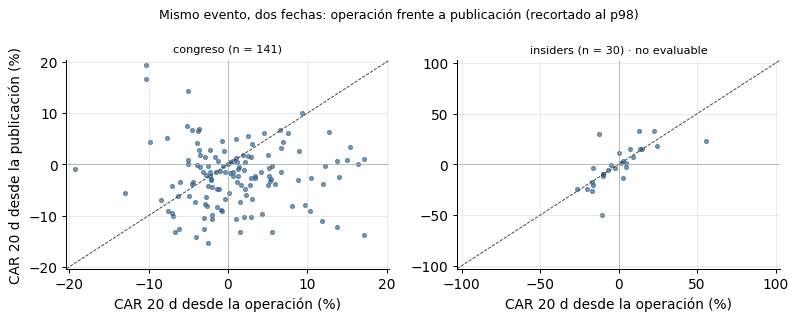

In [25]:
CAR = T['validez_car']
CEV = T['validez_car_eventos']
EVALUABLE = CAR.groupby('grupo')['pct_sin_precio'].first() <= va.MAX_SIN_PRECIO
for gname, g in CAR.groupby('grupo'):   # una figura por grupo: las escalas son muy distintas
    fig, axes = gr.car_grupos(g, nivel_ic=va.NIVEL_IC)
    fig.set_size_inches(6.4, 3.3)
    nota = '' if EVALUABLE[gname] else f'\nNO EVALUABLE: {g["pct_sin_precio"].iloc[0]:.0%} de eventos sin precio (supervivencia)'
    fig.suptitle(f'{gname}: CAR ajustado por SPY (media ± IC {va.NIVEL_IC:.0%} por semanas; n = {int(g["n"].max())}){nota}',
                 fontsize=9.5)
    fig.tight_layout()
    plt.show()

tabla9 = CAR.assign(**{c: (100 * CAR[c]).round(2) for c in ('car_medio', 'lo', 'hi')},
                    evaluable=CAR['grupo'].map(EVALUABLE))
display(tabla9.rename(columns={'car_medio': 'car_medio_%', 'lo': 'lo_%', 'hi': 'hi_%'}))

fig, axes = plt.subplots(1, CEV['grupo'].nunique(), figsize=(9, 3.6), squeeze=False)
for ax, (gname, g) in zip(axes[0], CEV.groupby('grupo')):
    g = g.dropna(subset=['car_20', 'car_20_desde_operacion'])
    ax.scatter(100 * g['car_20_desde_operacion'], 100 * g['car_20'], s=10, alpha=0.6, color=gr.C_BASE)
    lim = np.nanpercentile(100 * np.abs(g[['car_20', 'car_20_desde_operacion']].values), 98) if len(g) else 1
    ax.plot([-lim, lim], [-lim, lim], color='#333333', ls='--', lw=0.7)
    ax.axhline(0, color=gr.C_GRIS, lw=0.5)
    ax.axvline(0, color=gr.C_GRIS, lw=0.5)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel('CAR 20 d desde la operación (%)')
    ax.set_title(f'{gname} (n = {len(g)})' + ('' if EVALUABLE[gname] else ' · no evaluable'), fontsize=9)
axes[0, 0].set_ylabel('CAR 20 d desde la publicación (%)')
fig.suptitle('Mismo evento, dos fechas: operación frente a publicación (recortado al p98)', fontsize=10)
fig.tight_layout()
plt.show()

In [26]:
for gname, g in CAR.groupby('grupo'):
    r = g.set_index(['referencia_fecha', 'horizonte'])
    p, o = r.loc[('publicacion', 20)], r.loc[('operacion', 20)]
    if not EVALUABLE[gname]:
        print(f'{gname}: {int(p["n_eventos"])} eventos, {int(p["n_sin_precio"])} sin precio ({p["pct_sin_precio"]:.0%} > '
              f'{va.MAX_SIN_PRECIO:.0%}): CAR no evaluable por sesgo de supervivencia; no se interpreta.')
        continue
    pub = r.loc['publicacion']
    excl = [int(h) for h, x in pub.iterrows() if x['lo'] > 0 or x['hi'] < 0]
    print(f'{gname}: {int(p["n_eventos"])} eventos ({int(p["n_semanas"])} semanas), {int(p["n_sin_precio"])} sin precio. '
          f'CAR 20 d desde publicación {100 * p["car_medio"]:+.2f} % [{100 * p["lo"]:+.2f}; {100 * p["hi"]:+.2f}] '
          f'(n={int(p["n"])}) frente a {100 * o["car_medio"]:+.2f} % [{100 * o["lo"]:+.2f}; {100 * o["hi"]:+.2f}] desde la '
          f'operación. Horizontes con IC sin el 0 desde la publicación: {excl or "ninguno"} de {list(pub.index)}.')

congreso: 152 eventos (22 semanas), 10 sin precio. CAR 20 d desde publicación -1.24 % [-2.08; +0.39] (n=141) frente a +0.80 % [-0.11; +1.84] desde la operación. Horizontes con IC sin el 0 desde la publicación: ninguno de [5, 20, 60].
insiders: 60 eventos, 27 sin precio (45% > 20%): CAR no evaluable por sesgo de supervivencia; no se interpreta.


## 10. Semáforo final

Cada candidato (serie, fuente de texto o alternativo de evento) recibe 0-2 puntos en cinco criterios:

- **historia**: crisis de la Fase 1 cubiertas (en Congreso y Form 4, las de la muestra en la que se mide el CAR);
- **calidad**: huecos (las fuentes congeladas no pasan de 1; una racha de valores idénticos de `validez.RACHA_MALA`
  o más, hueco codificado como constante, da 0);
- **lookahead**: peor resultado de sus comprobaciones (fallo 0, riesgo 1, ok 2);
- **senal**: series: AUC con adelanto 0 en los días del VIX, contado solo en el sentido esperado
  (`SIGNO_ESPERADO`; sin signo a priori no hay señal) y solo si su IC por bloques de crisis excluye 0,5 y el estudio de
  eventos va en el mismo sentido; Congreso y Form 4: IC por semanas del CAR sin el 0 en al menos 2 de los 3 horizontes
  con el mismo signo (sin señal si falta precio en demasiados eventos); mercados de predicción: Brier por debajo del
  climatológico entre los mercados indecisos a 7 d;
- **acceso**: estado de la sonda (ok 2, parcial o congelada 1, fallo o no probada 0).

Reglas del veredicto (`validez.veredicto`), en orden: acceso 0, look-ahead 0 o calidad 0 → `descartar`;
historia 0 → `solo_vivo`; texto: historia 2 → `apta_backtest` (cajón RAG) e historia 1 → `contexto`; series y eventos:
historia 1 → `solo_vivo`, sin medida de señal → `contexto`, señal ≥ 1 → `apta_backtest` y señal 0 → `contexto`.

**Cómo leerlo.** Filas agrupadas por veredicto; última columna separada por la línea negra. Celdas grises: el criterio
no aplica (las fuentes de texto no tienen AUC).

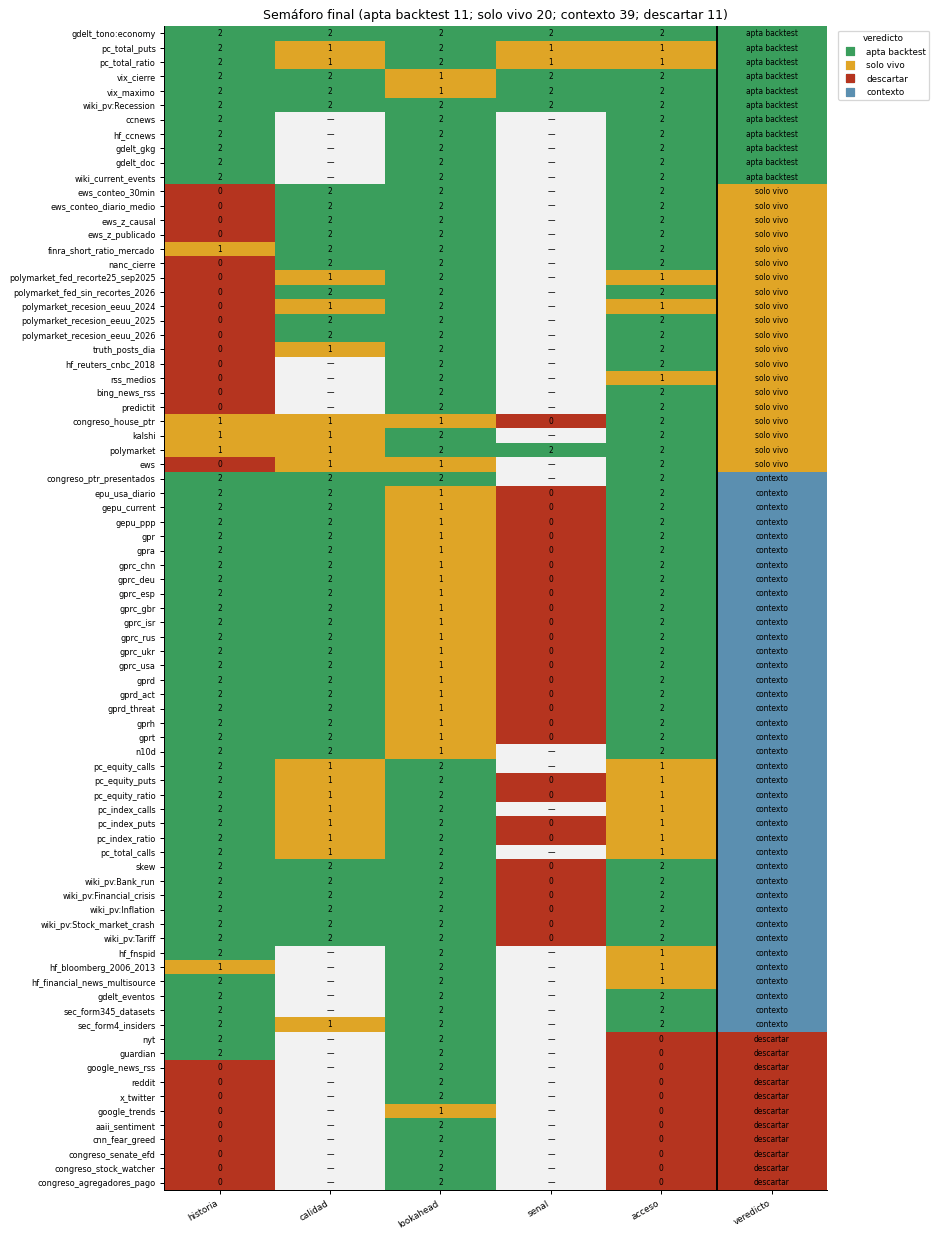

veredicto,apta_backtest,solo_vivo,contexto,descartar,total
tipo,,,,,
evento,0,5,3,6,14
serie,6,12,33,0,51
texto,5,3,3,5,16
total,11,20,39,11,81


In [27]:
fig, ax = gr.semaforo_final(SEM)
plt.show()
orden_v = list(gr.ORDEN_VEREDICTO)
display(pd.crosstab(SEM['tipo'], SEM['veredicto'], margins=True, margins_name='total')
        .reindex(columns=[v for v in orden_v if v in set(SEM['veredicto'])] + ['total']))

In [28]:
tabla10 = (SEM.assign(_o=SEM['veredicto'].map({v: i for i, v in enumerate(orden_v)}))
           .sort_values(['_o', 'tipo', 'candidato'])
           [['candidato', 'tipo', 'n_crisis', 'veredicto', 'metrica_senal', 'motivo']].reset_index(drop=True))
display(tabla10)

,candidato,tipo,n_crisis,veredicto,metrica_senal,motivo
0,gdelt_tono:economy,serie,6,apta_backtest,"AUC h=0 0.327 [0.278, 0.456] en los días del VIX (VIX 0.785); otros adelantos: h=20 0.340, h=60 0.442; sig...",cubre crisis y separa crisis de no crisis en el sentido esperado
1,pc_total_puts,serie,6,apta_backtest,"AUC h=0 0.626 [0.569, 0.682] en los días del VIX (VIX 0.799); otros adelantos: h=20 0.595, h=60 0.558; sig...",cubre crisis y separa crisis de no crisis en el sentido esperado (acceso parcial o fuente congelada: solo ...
2,pc_total_ratio,serie,6,apta_backtest,"AUC h=0 0.642 [0.569, 0.732] en los días del VIX (VIX 0.799); otros adelantos: h=20 0.606, h=60 0.578; sig...",cubre crisis y separa crisis de no crisis en el sentido esperado (acceso parcial o fuente congelada: solo ...
3,vix_cierre,serie,12,apta_backtest,"AUC h=0 0.800 [0.706, 0.859] en los días del VIX (VIX 0.800); otros adelantos: h=20 0.743, h=60 0.699; sig...",cubre crisis y separa crisis de no crisis en el sentido esperado (look-ahead con riesgo documentado: ver v...
4,vix_maximo,serie,12,apta_backtest,"AUC h=0 0.798 [0.705, 0.858] en los días del VIX (VIX 0.800); otros adelantos: h=20 0.741, h=60 0.697; sig...",cubre crisis y separa crisis de no crisis en el sentido esperado (look-ahead con riesgo documentado: ver v...
5,wiki_pv:Recession,serie,6,apta_backtest,"AUC h=0 0.815 [0.678, 0.862] en los días del VIX (VIX 0.818); otros adelantos: h=20 0.707, h=60 0.588; sig...",cubre crisis y separa crisis de no crisis en el sentido esperado
6,ccnews,texto,6,apta_backtest,cobertura por épocas (ok),texto con cobertura de varias crisis y fecha de publicación fiable (cajón RAG)
7,gdelt_doc,texto,6,apta_backtest,cobertura por épocas (ok),texto con cobertura de varias crisis y fecha de publicación fiable (cajón RAG)
8,gdelt_gkg,texto,7,apta_backtest,cobertura por épocas (ok),texto con cobertura de varias crisis y fecha de publicación fiable (cajón RAG)
9,hf_ccnews,texto,5,apta_backtest,cobertura por épocas (ok),texto con cobertura de varias crisis y fecha de publicación fiable (cajón RAG)


## 11. Conclusiones: qué entra en el backtest, qué solo en vivo y qué se descarta

- `apta_backtest`: entra en la base de series del TimeGate (o en el cajón RAG, si es texto) y se puede usar en el
  backtest desde su inicio, con la fecha de publicación medida aquí.
- `contexto`: se guarda y el agente la puede consultar, pero no se le da peso como señal de crisis (cubre las crisis y
  no las separa, o no hay medida de señal).
- `solo_vivo`: se archiva cada día desde ahora; no hay historia suficiente para validarla.
- `descartar`: no se ingesta (acceso fallido o no probado, o look-ahead sin arreglo).

Listas y motivos impresos desde `validez_semaforo`:

In [29]:
for v in orden_v:
    g = SEM[SEM['veredicto'] == v]
    if g.empty:
        continue
    print(f'\n{v.upper()} ({len(g)})')
    for tipo, h in g.groupby('tipo'):
        print(f'  {tipo} ({len(h)}): ' + ', '.join(h['candidato']))
    for m, n in g['motivo'].value_counts().items():
        print(f'    · {n} × {m}')


APTA_BACKTEST (11)
  serie (6): gdelt_tono:economy, pc_total_puts, pc_total_ratio, vix_cierre, vix_maximo, wiki_pv:Recession
  texto (5): ccnews, hf_ccnews, gdelt_gkg, gdelt_doc, wiki_current_events
    · 5 × texto con cobertura de varias crisis y fecha de publicación fiable (cajón RAG)
    · 2 × cubre crisis y separa crisis de no crisis en el sentido esperado
    · 2 × cubre crisis y separa crisis de no crisis en el sentido esperado (acceso parcial o fuente congelada: solo backtest hasta su fin)
    · 2 × cubre crisis y separa crisis de no crisis en el sentido esperado (look-ahead con riesgo documentado: ver validez_lookahead)

SOLO_VIVO (20)
  evento (5): predictit, congreso_house_ptr, kalshi, polymarket, ews
  serie (12): ews_conteo_30min, ews_conteo_diario_medio, ews_z_causal, ews_z_publicado, finra_short_ratio_mercado, nanc_cierre, polymarket_fed_recorte25_sep2025, polymarket_fed_sin_recortes_2026, polymarket_recesion_eeuu_2024, polymarket_recesion_eeuu_2025, polymarket_recesion_

In [30]:
ap = SEM[(SEM['veredicto'] == 'apta_backtest') & (SEM['tipo'] == 'serie')]
a0 = AUC[(AUC['adelanto'] == 0) & AUC['serie'].isin(ap['candidato'])].set_index('serie')
print('Series aptas: AUC con adelanto 0 en los días del VIX, IC por bloques de crisis y signo esperado:')
for s_, r in a0.sort_values('auc_mismo_periodo', ascending=False).iterrows():
    sg = va.signo_esperado(s_)
    print(f'  {s_}: AUC {r.auc_mismo_periodo:.3f} [{r.auc_lo:.3f}, {r.auc_hi:.3f}] (VIX {r.auc_vix_mismo_periodo:.3f}; '
          f'signo esperado {"+" if sg > 0 else "−"}; {int(r.n_crisis_mismo_periodo)} crisis)')
contra = SEM[SEM['metrica_senal'].astype(str).str.contains('contrario')]
print(f'Con el AUC o el estudio de eventos en contra del signo esperado ({len(contra)}): {", ".join(contra["candidato"])}.')
sin_signo = SEM[SEM['metrica_senal'].astype(str).str.contains('sin signo esperado')]
print(f'Sin signo esperado a priori ({len(sin_signo)}): {", ".join(sin_signo["candidato"])}.')
congel = SEM[(SEM['veredicto'] == 'apta_backtest') & (SEM['acceso'] == 1)]
print(f'Aptas solo hasta su fin (acceso parcial o fuente congelada): {", ".join(congel["candidato"]) or "ninguna"}.')

Series aptas: AUC con adelanto 0 en los días del VIX, IC por bloques de crisis y signo esperado:
  wiki_pv:Recession: AUC 0.815 [0.677, 0.862] (VIX 0.818; signo esperado +; 6 crisis)
  vix_cierre: AUC 0.800 [0.706, 0.859] (VIX 0.800; signo esperado +; 12 crisis)
  vix_maximo: AUC 0.798 [0.705, 0.858] (VIX 0.800; signo esperado +; 12 crisis)
  pc_total_ratio: AUC 0.642 [0.569, 0.732] (VIX 0.799; signo esperado +; 6 crisis)
  pc_total_puts: AUC 0.626 [0.569, 0.682] (VIX 0.799; signo esperado +; 6 crisis)
  gdelt_tono:economy: AUC 0.327 [0.278, 0.456] (VIX 0.785; signo esperado −; 6 crisis)
Con el AUC o el estudio de eventos en contra del signo esperado (12): gepu_current, gepu_ppp, gprc_chn, gprc_deu, gprc_gbr, gprc_rus, gprc_ukr, gprt, pc_equity_ratio, wiki_pv:Financial_crisis, wiki_pv:Inflation, wiki_pv:Tariff.
Sin signo esperado a priori (7): congreso_ptr_presentados, finra_short_ratio_mercado, n10d, pc_equity_calls, pc_index_calls, pc_total_calls, truth_posts_dia.
Aptas solo hasta su

## 12. Resumen para la reunión

Cifras impresas desde las tablas anteriores (nada escrito a mano).

In [31]:
cv = SEM['veredicto'].value_counts()
vix0 = AUC[(AUC['serie'] == va.SERIE_VIX) & (AUC['adelanto'] == 0)].iloc[0]
otras0 = AUC[(AUC['adelanto'] == 0) & ~AUC['serie'].isin(va.SERIES_REFERENCIA)].dropna(subset=['auc_mismo_periodo'])
riesgos = sorted(LA.loc[LA['resultado'] == 'riesgo', 'comprobacion'].unique())
ind7 = CALB[(CALB['horizonte_dias'] == 7) & (CALB['liquidez'] == 'indeciso')].set_index('plataforma')
tod7 = CALB[(CALB['horizonte_dias'] == 7) & (CALB['liquidez'] == 'todos')].set_index('plataforma')
z_ser = LA[LA['comprobacion'] == 'normalizacion_sin_futuro_serie']
print('VALIDEZ DE NOTICIAS Y DATOS ALTERNATIVOS (Tema 4, B2)')
print(f'· Evaluados {len(SEM)} candidatos ({", ".join(f"{k} {v}" for k, v in SEM["tipo"].value_counts().items())}): '
      + ', '.join(f'{k} {cv.get(k, 0)}' for k in orden_v) + '.')
print(f'· Rejilla as-of por publicación: {REJ.shape[1]} series, {REJ.index.min():%Y}-{REJ.index.max():%Y}; '
      f'{len(CRISIS)} crisis de la Fase 1 como etiqueta.')
print(f'· Look-ahead: {len(LA)} comprobaciones, {int((LA["resultado"] == "fallo").sum())} fallos y '
      f'{int((LA["resultado"] == "riesgo").sum())} riesgos ({", ".join(riesgos)}).')
print(f'· z causal con el pipeline rehecho en cortes: {len(z_ser)} series cambian ({", ".join(z_ser["fuente"])}), por la '
      'elección log/nivel con la serie entera.')
print(f'· Control: AUC del VIX {vix0["auc"]:.3f} [{vix0["auc_lo"]:.3f}, {vix0["auc_hi"]:.3f}] con adelanto 0 '
      f'({int(vix0["n_crisis"])} crisis). {int((otras0["auc_mismo_periodo"] > otras0["auc_vix_mismo_periodo"]).sum())} de '
      f'{len(otras0)} series lo superan en los mismos días.')
o5 = otras0[otras0['n_crisis_mismo_periodo'] >= va.CRISIS_BUENA]
mej = o5.loc[(o5['auc_mismo_periodo'] - 0.5).abs().idxmax()]
print(f'· Mayor |AUC − 0,5| con adelanto 0 en los días del VIX (≥ {va.CRISIS_BUENA} crisis): {mej["serie"]} '
      f'{mej["auc_mismo_periodo"]:.3f} [{mej["auc_lo"]:.3f}, {mej["auc_hi"]:.3f}] (VIX {mej["auc_vix_mismo_periodo"]:.3f}, '
      f'{int(mej["n_crisis_mismo_periodo"])} crisis).')
ind_ref = LLR['lag_max_ref'].isna().mean()
ind_pub = LLR['lag_max_pub'].isna().mean()
print(f'· Lead-lag: lag indeterminado (no se distingue del 0) en el {ind_ref:.0%} de las comparaciones por fecha de '
      f'referencia y en el {ind_pub:.0%} por publicación; ninguna lectura de «quién va antes» sin separar las dos rejillas.')
for pl in ind7.index:
    i, t = ind7.loc[pl], tod7.loc[pl]
    print(f'· {pl}, 7 d: indecisos Brier {i["brier"]:.3f} frente a {i["brier_clima"]:.3f} (n={int(i["n"])}); todos '
          f'{t["brier"]:.3f} frente a {t["brier_clima"]:.3f} (n={int(t["n"])}, {int(t["n_decididos"])} ya decididos).')
for gname, g in CAR[CAR['referencia_fecha'] == 'publicacion'].groupby('grupo'):
    if not EVALUABLE[gname]:
        print(f'· {gname}: CAR no evaluable ({g["pct_sin_precio"].iloc[0]:.0%} de eventos sin precio: supervivencia).')
        continue
    excl = [int(x.horizonte) for x in g.itertuples() if x.lo > 0 or x.hi < 0]
    p20 = g.set_index('horizonte').loc[20]
    print(f'· {gname}: CAR 20 d desde la publicación {100 * p20["car_medio"]:+.2f} % [{100 * p20["lo"]:+.2f}; '
          f'{100 * p20["hi"]:+.2f}] (IC por semanas, n={int(p20["n"])}); horizontes con IC sin el 0: {excl or "ninguno"}.')
print(f'· Aptas para backtest: {", ".join(SEM.loc[SEM["veredicto"] == "apta_backtest", "candidato"])}.')
print(f'· Solo en vivo: {", ".join(SEM.loc[SEM["veredicto"] == "solo_vivo", "candidato"])}.')
print('\nPara decidir en grupo: umbrales del semáforo y SIGNO_ESPERADO, si las series «contexto» entran como features '
      'sin peso, fijar la transformación log/nivel a priori (hoy usa la serie entera), qué hacer con los vintages '
      'revisados (GPR, EPU) y cuándo empezar a archivar las fuentes solo en vivo.')

VALIDEZ DE NOTICIAS Y DATOS ALTERNATIVOS (Tema 4, B2)
· Evaluados 81 candidatos (serie 51, texto 16, evento 14): apta_backtest 11, solo_vivo 20, contexto 39, descartar 11.
· Rejilla as-of por publicación: 51 series, 1985-2026; 18 crisis de la Fase 1 como etiqueta.
· Look-ahead: 116 comprobaciones, 0 fallos y 29 riesgos (ews_z_publicado_vs_causal, normalizacion_expanding_sin_futuro, normalizacion_sin_futuro_serie, ptr_lag_operacion_publicacion, trends_renormalizacion, valor_revisado_vintage_actual).
· z causal con el pipeline rehecho en cortes: 6 series cambian (epu_usa_diario, gprc_chn, gprc_rus, gprd, vix_cierre, vix_maximo), por la elección log/nivel con la serie entera.
· Control: AUC del VIX 0.800 [0.706, 0.859] con adelanto 0 (12 crisis). 0 de 40 series lo superan en los mismos días.
· Mayor |AUC − 0,5| con adelanto 0 en los días del VIX (≥ 5 crisis): wiki_pv:Recession 0.815 [0.677, 0.862] (VIX 0.818, 6 crisis).
· Lead-lag: lag indeterminado (no se distingue del 0) en el 58% de la